In [ ]:
import numpy as np
import scipy as sp
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from pyXSteam.XSteam import XSteam
from fuel_conduction_Model import Fuel
import time
from scipy.special import j1

# time tracking
start = time.time()
time_calculating_transient_fuel_nodes = 0

# Parameters
evaluate_hot = True
evaluate_CHF = True
pump_trip_transient = True
nonlinear_PK = True # True to use p(T_M, C_B) and False to use alpha_B and alpha_M
feedwater_loss_transient = False

if pump_trip_transient and feedwater_loss_transient:
    raise ValueError('Cannot run 2 transients simultaneously')
evaluate_CHF = evaluate_hot and evaluate_CHF #CHF is evaluated only if hot channel is also evaluated
steamTable = XSteam(XSteam.UNIT_SYSTEM_MKS)
# Physical data
L_a = 27.652 # [m]  Channel length
L_b = 22.948 # [m]
L_c = 123.448 # [m]
g = 9.81 #m/s^2
A_a_in = 80.0 #m^2
Dh_a = np.sqrt(4 * A_a_in / np.pi) #m
roughness_else = 0.07 * 1e-3 #m

Dh_b = 3.75 #m Equivalent core diameter (checked)
A_core = 6.065 #m^2 (checked) flow area through the core region
roughness_core = 0.004 * 1e-3 #m
A_b = (Dh_b / 1.15)**2 / 4 *np.pi #m^2 assumed from drawing
n_tubes_LDl = 2000 # number of tubes per bundle in density lock
n_tubes_UDl = n_tubes_LDl * 2
id_tube = 55 #[mm] inner diameter tube in density lock [checked]
A_LDl = (id_tube*1e-3 * np.pi / 4)**2 * n_tubes_LDl # (3 / 8 * Dh_b) **2 / 4 * np.pi * 0.5 # flow area through the density locks [checked]
A_UDl = (id_tube*1e-3 * np.pi / 4)**2 * n_tubes_UDl
L_Udl = 1 # m, Upper density lock length 
L_Ldl = 1# 2.352 # m LDL length
L_lower_plenum = 2.352 #m
L_interface_U = L_Udl * 0.5  # m, position of the interface between primary loop and pool from beginning of Ch. A relative to density lock length
L_interface_L = L_a - L_Ldl * 0.5
# Coolant and reactivity parameters
nominal_mass_flow = 13000 # [Kg/s], nominal s.s. flow rate in the primary loop (checked)
P_initial = 90.0 #bar (checked)
T_l = 260.0 # °C # T lower lock in channel b (checked)
T_u = 290.0 # °C T at upper lock in channel b (checked)
T_pool = 50.0 # °C (checked)
SS_boron_concentration = 375 # ppm
Boron_concentration_pool = 2200 - SS_boron_concentration  # ppm, the whole boron concentration is shifted by SS_boron_concentration so numerical SS core boron concentration is 0
alpha_B = -13.1 # [pcm / ppm] boron coefficient
alpha_M = - 46  # [pcm/ C°] moderator temperature coefficient (checked, avg between BOC(46) and EOC(36)) (checked)
alpha_doppler = - 3.1 # [pcm/ C°] Fuel doppler temperature coefficient (checked)
# [c00, c01, c02, c03, c10, c11, c12, c20, c21, c30] and for example c01 * C_B while c21 * T_M**2 * C_B
MB_3rd_degree_polynomial_interpolation_coeffs = [12883.547278312572,-15.94058317172585,0.0008132892550489924,-2.7885171505204198e-08,-9.889152641771075,-0.0074219697917788045,-1.400225604797356e-06,0.054497425990448954,6.160985103154104e-05,-0.00019618935106205382]
T_sg_sat = steamTable.tsat_p(39) # Saturation temperature of feedwater
# Spatial Mesh
nx_a = 200
nx_b = 100
nx_c = 100
#channel A
dx_a = L_a/ (nx_a - 1)
x_a = np.linspace(0, L_a, nx_a)
n_Udl= int(L_Udl / dx_a) # number of nodes in Upper density lock
n_Ldl = int(L_Ldl / dx_a) # in LDL
n_lower_plenum = int(L_lower_plenum / dx_a)
n_interface_Ldl = int((L_a - L_interface_L) / dx_a)
if n_interface_Ldl == 0 :
    n_interface_Ldl = 1
n_interface_Udl = int(L_interface_U/ dx_a)
if n_interface_Udl == 0 :
    n_interface_Udl = 1
#channel B
dx_b = L_b/ (nx_b - 1)
x_b = np.linspace(0, L_b, nx_b)

#channel C
dx_c = L_c/ (nx_c - 1)
x_c = np.linspace(0, L_c, nx_c) 

# Time mesh
Time = 30 # s , target time
delta_time = 0.25 # s, hopeful time interval, must be a float (1.0 instead of 1)
nt = int(Time / delta_time) # number of time steps
t = np.zeros(nt) # time array 
delta_time_target = delta_time

# Angles
Theta_a = np.where((x_a >= L_a - L_lower_plenum), np.pi, 0) # tilt angle of the channel
Theta_b = np.full(nx_b, np.pi)
channel_c_sector = [(x_c < 13.25),
    (x_c >= 13.25) & (x_c < 38.25),
    (x_c >= 38.25) & (x_c < 53.25),
    (x_c >= 53.25) & (x_c < 68.25),
    (x_c >= 68.25) & (x_c < 87.25),
    (x_c >= 87.25)]
angles_c = [np.pi, 
    np.pi / 2, 
    0, 
    np.pi, 
    np.pi / 2, 
    0]
A_c_hl = 0.665 # [m^2]
A_c_SG = 4.406 # [m^2]
A_c_cl = 0.635 # [m^2]
A_c_downcomer = 2.5 # [m^2]
areas_c = [A_b,
           A_c_hl,
           A_c_SG,
           A_c_cl,
           A_c_cl,
           A_c_downcomer]
Theta_c = np.select(channel_c_sector, angles_c) #(checked)
# Core and SG settings
Q_core_SS = 2e6 # [kW], also equal to HX heat removal power in SS (checked)
H_core = 2.5 # Active core height (checked)
H_SG = 15 # [m] (checked)
R_core = Dh_b / 2 # core radius (checked)
x_start_core = 1  # Core placement from bottom of channel B [m]
x_start_SG = 38.25  # SG placement from top of channel C [m]
idx_start_core = np.abs(x_b - x_start_core).argmin()
idx_exit_core = np.abs(x_b - (x_start_core + H_core)).argmin()
idx_start_SG = np.abs(x_c - x_start_SG).argmin()
idx_exit_SG = np.abs(x_c - (x_start_SG + H_SG)).argmin()
n_pump = int(idx_exit_SG + 1) #the pump is at exit of SG
x_core = x_b [idx_start_core : idx_exit_core]
A_b_array = np.full(nx_b, A_b)
A_b_array[idx_start_core : idx_exit_core] = A_core
A_a_array = np.full(nx_a, A_a_in)
A_a_array[0 : n_Udl] = A_UDl
A_a_array[-n_Ldl:] = A_LDl
A_c_array = np.select(channel_c_sector, areas_c)
# power distribution
# peaking factors (careful that they are capped by nature) and extrapolation dimensions calculation
f_A = 1.4 # axial peaking gactor (checked)
f_R_channel = 1.55 # radial channel-wise peaking factor (for the mass flux) (checked)
f_channel = 1.2 # radial, within channel, peaking factor
f_R = f_R_channel * f_channel  # total radial peaking factor (for the power)

def f_A_minimize(H_core_tilde):
    return np.pi * H_core / (2 * H_core_tilde * np.sin(np.pi / 2 * H_core / H_core_tilde)) - f_A
def f_R_minimize(R_core_tilde):
    return 2.405 * R_core / (2 * R_core_tilde * j1(2.405 * R_core / R_core_tilde)) - f_R
H_core_tilde = sp.optimize.fsolve(f_A_minimize, 1.2 * H_core)[0] # 1.2 * H_core for the initial guess
R_core_tilde = sp.optimize.fsolve(f_R_minimize, 1.2 * R_core)[0] # 1.2 * R_core for the initial guess
# print(f"H_tilde / H = {H_core_tilde / H_core}")
# print(f"R_tilde / R = {R_core_tilde / R_core}")


# fuel and lattice
n_fuel_assembly = 213 # [-] (checked)
n_rods_assembly = 316 #[-] (checked)
number_pins = n_fuel_assembly * n_rods_assembly  # [-]
d_r = 0.0095 # [m] , rod diameter (checked)
r_co = d_r / 2 # [m] 
r_go = r_co - 0.000572 # [m] (checked)
r_fo = 0.00819  / 2 # [m] (checked)
pitch = 0.0126 # [m], lattice pitch (checked)
D_h = d_r * (4 / np.pi * (pitch / d_r)**2 - 1) # hydraulic diameter
Dh_c = np.sqrt(4 * A_c_array / np.pi) #m

P_H = number_pins * 2 * np.pi * r_co
V_fuel = number_pins * np.pi * r_fo**2 * H_core
V_core = Dh_b ** 2 / 4 * np.pi * H_core 
A_cladding_core = P_H * H_core #[m^2]
average_surface_heat_flux_kWm2 = Q_core_SS / A_cladding_core #[kW / m^2] consistent with data
x_start_core_eff = x_b[idx_start_core]
H_core_eff  = x_b[idx_exit_core] - x_b[idx_start_core]
heat_flux_kWm2 = np.sin((x_core[1:] - x_start_core_eff) * np.pi / H_core_eff) * average_surface_heat_flux_kWm2 * np.pi / 2
heat_flux_hot_channel_kWm2 = heat_flux_kWm2 * f_R
average_linear_heat_flux_kWm = Q_core_SS / (number_pins * H_core)
average_fuel_volumetric_heating_SS_kW = Q_core_SS / V_fuel
average_fuel_volumetric_heating_SS_W = average_fuel_volumetric_heating_SS_kW * 1000

peak_fuel_volumetric_heating_SS_W = average_fuel_volumetric_heating_SS_W * f_A * f_R


def Dittus_Boetler_h(local_pressure, local_temperature, mb_0):
    # Dittus Boetler
    # local coolant properties, at initial pressure and liquid bulk temperature (approximation, could use mean of liquid bulk and outer cladding)
    rho_loc = steamTable.rho_pt(local_pressure, local_temperature) # local density
    c_p_loc = steamTable.Cp_pt(local_pressure, local_temperature) * 1e3 # local specific heat in SI units
    k_loc = steamTable.tc_pt(local_pressure, local_temperature) # local thermal conductivity
    my_loc = steamTable.my_pt(local_pressure, local_temperature)  # local viscosity
    G_loc = mb_0 / A_core # mass flux
    Re_loc = G_loc * D_h / my_loc # local Reynolds
    Pr_loc = c_p_loc * my_loc / k_loc # local Prandelt
    Nu_loc = 0.023 * Re_loc**0.8 * Pr_loc**0.4  # Dittus Boetler (for heating => power of 0.4), local Nusselt
    h_loc = k_loc * Nu_loc / D_h # local heat transfer coefficient with hydraulic diameter as characteristic length
    if Re_loc < 1e4:
        print(f"Re outside of Dittus Boetler validity range")
    #print(f"Pr : {Pr_loc}")
    if Pr_loc < 0.7 or Pr_loc > 100:
        print(f"Pr outside of Dittus Boetler validity range")
    return h_loc

def CHF_Reddyfighetti(x, mass_flux, p, q2):
    x_in = x[0]
    G_r = mass_flux / 1356.23
    p_cr = 220e5
    p = p * 1e5
    p_r = p / p_cr
    q_r = q2 / 3.1544e6
    q_r[0] = 1e-6
    a1 = 0.5328
    a2 = 0.1212
    a3 = -0.3040
    a4 = 0.3285
    c1 = 1.6151
    c2 = 1.4066
    c3 = 0.4843
    c4 = -2.0749
    A = a1 * p_r ** a2 * G_r ** (a3 + a4 * p_r)
    B = 3.1544e6
    C = c1 * p_r ** c2 * G_r ** (c3 + c4 * p_r)
    q_cr = B * (A - x_in) / (C + (x - x_in) / (q_r))
    return q_cr

S_b_correction_factor = 1.0 # ensure target core power generation is met
def S_b_func(core, n):
    # returns volumetric power to the coolant in channel b based on the core object array at time n
    toReturn = np.zeros(len(core))
    last = 0
    for i in range(len(core)):
        if core[i] is not None: 
            toReturn[i] = core[i].hf_co[n] * P_H / A_core # volumetric power in the coolant from fuel heat flux
            last=i
        else:
            toReturn[i] = 0
    print(f"core[{last}].hf_co[{n}] = {core[last].hf_co[n]}")
    print(f"core[{last}].volumetric_heating[{n}] : {core[last].volumetric_heating[n]}")
    print(f"core[{last}].T_lb[{n}] : {core[last].T_lb[n]}")
    return toReturn / 1000.0 # Hydraulics uses kW and fuel uses W

def S_a_func(total_time):
    return np.zeros(nx_a)

S_c_correction_factor = 1.0  # ensure target HX power removal is met
def S_c_func(total_time):
    if pump_trip_transient:
        S_c_transient = np.where((x_c >= x_start_SG) & (x_c <= x_start_SG + H_SG), -Q_core_SS / H_SG * S_c_correction_factor, 0) / A_c_SG * ((total_time <= 0.1) + (total_time >= 0.1) * (total_time <= 18) * (0.75 + 0.25 * (np.exp( - (total_time - 0.1) / 4.3))) +  0.75 * (total_time > 18) * (np.exp( - (total_time - 18) / .2)))
    elif feedwater_loss_transient:
        S_c_transient = np.where((x_c >= x_start_SG) & (x_c <= x_start_SG + H_SG), -Q_core_SS / H_SG * S_c_correction_factor, 0) / A_c_SG * ((total_time <= 0.1) + (total_time >= 0.1) * (total_time <= 35) * (0.75 + 0.25 * 4 * (np.exp( - (total_time - 0.1) / 5))) +  0.75 * (total_time > 35) * (np.exp( - (total_time - 35) / 1.5)))
    else :
        S_c_transient = np.where((x_c >= x_start_SG) & (x_c <= x_start_SG + H_SG), -Q_core_SS / H_SG * S_c_correction_factor, 0) / A_c_SG
    return S_c_transient

# core object with fuel nodes. Averaged for system modeling. Will be re-created later with corrected volumetric heating
core = np.array([
    Fuel(len(t), peak_fuel_volumetric_heating_SS_W / f_R * np.cos(np.pi * (x_b[i] - (x_start_core + H_core / 2.0)) / H_core_tilde), None, None)
    if i >= idx_start_core and i < idx_exit_core
    else None
    for i in range(len(x_b))
], dtype=object) # np.where was putting the same Fuel object everywhere

# Power distribution and correction factors
S_a = np.zeros(nx_a)

# pre-correction
S_b = S_b_func(core, 0)
S_c = S_c_func(0)
Total_P_b_SS = np.sum(S_b[:-1]) * dx_b * A_core # W
Total_P_c_SS = np.sum(S_c[:-1]) * dx_c * A_c_SG # W
S_b_correction_factor = Q_core_SS / Total_P_b_SS
S_c_correction_factor = - Q_core_SS / Total_P_c_SS

# post-correction, recreate the nodes from volumetric heating with the correction factor for proper initialization sequence
core = np.array([
    Fuel(len(t), peak_fuel_volumetric_heating_SS_W * S_b_correction_factor / f_R * np.cos(np.pi * (x_b[i] - (x_start_core + H_core / 2.0)) / H_core_tilde), None, None)
    if i >= idx_start_core and i < idx_exit_core
    else None
    for i in range(len(x_b))
], dtype=object) # np.where was putting the same Fuel object everywhere
# core object with hot pin fuel nodes. For limit temperature and CHF modeling
if evaluate_hot:
    core_hot = np.array([
        Fuel(len(t), peak_fuel_volumetric_heating_SS_W * S_b_correction_factor * np.cos(np.pi * (x_b[i] - (x_start_core + H_core / 2.0)) / H_core_tilde), None, None)
        if i >= idx_start_core and i < idx_exit_core
        else None
        for i in range(len(x_b))
    ], dtype=object)
            
S_b = S_b_func(core, 0)
S_c = S_c_func(0)
if evaluate_hot : 
    S_b_hot = S_b_func(core_hot, 0)
    
print(f"Total_P_b before correction = {Total_P_b_SS} and Q_core_SS = {Q_core_SS} so S_b_correction_factor = {S_b_correction_factor}")
print(f"Total_P_c before correction = {Total_P_c_SS} and Q_core_SS = {Q_core_SS} so S_c_correction_factor = {S_c_correction_factor}")
Total_P_b_SS = np.sum(S_b[:-1]) * dx_b * A_core # W
Total_P_c_SS = np.sum(S_c[:-1]) * dx_c * A_c_SG # W
print(f"Total_P_b after correction = {Total_P_b_SS}")
print(f"Total_P_c after correction = {Total_P_c_SS}")

Total_P_b = np.zeros(len(t)) # power to coolant in channel B
Total_P_b[0] = Total_P_b_SS
Total_P_c = np.zeros(len(t)) # power to coolant in channel B
Total_P_c[0] = Total_P_c_SS


#Retrieve densities from steam table
def get_rho(Enthalpy, Pressure):
    # Convert inputs to numpy arrays to handle both scalars and lists/arrays
    i = np.atleast_1d(Enthalpy)
    P = np.atleast_1d(Pressure)
    if i.size != P.size:
        if P.size == 1:
            P = np.full_like(i, P)
        elif i.size == 1:
            i = np.full_like(P, i)
        else:
            raise ValueError("Enthalpy and Pressure arrays must be the same size, or one must be a scalar.")
        v_rho_pi = np.vectorize(steamTable.rho_ph)
    return v_rho_pi(P, i)

def Colebrook(roughness, diameter, Reynolds):
    LHS = -3.6 * np.log10((roughness / diameter * 1/3.7)**1.11 + 6.9 / Reynolds)
    return (1 / LHS)**2

def Reynolds(G, diameter, viscosity):
    return G * diameter / viscosity

#Retrieve specifi heat from steam table
def get_cp(Enthalpy, Pressure):
    # Convert inputs to numpy arrays to handle both scalars and lists/arrays
    i = np.atleast_1d(Enthalpy)
    P = np.atleast_1d(Pressure)
    if i.size != P.size:
        if P.size == 1:
            P = np.full_like(i, P)
        elif i.size == 1:
            i = np.full_like(P, i)
        else:
            raise ValueError("Enthalpy and Pressure arrays must be the same size, or one must be a scalar.")
        v_cp_pi = np.vectorize(steamTable.Cp_ph)
    return v_cp_pi(P, i)

def get_T_from_i(Enthalpy, Pressure):
    i = np.atleast_1d(Enthalpy)
    P = np.atleast_1d(Pressure)
    il_sat = steamTable.hL_p(Pressure)
    i = np.minimum(i, il_sat)
    if i.size != P.size:
        if P.size == 1:
            P = np.full_like(i, P)
        elif i.size == 1:
            i = np.full_like(P, i)
        else:
            raise ValueError("Enthalpy and Pressure arrays must be the same size, or one must be a scalar.")
        v_T_pi = np.vectorize(steamTable.t_ph)
    return v_T_pi(P, i)


def get_quality(Enthalpy, Pressure):
    i = np.atleast_1d(Enthalpy)
    P = np.atleast_1d(Pressure)
    if i.size != P.size:
        if P.size == 1:
            P = np.full_like(i, P)
        elif i.size == 1:
            i = np.full_like(P, i)
        else:
            raise ValueError("Enthalpy and Pressure arrays must be the same size, or one must be a scalar.")
        v_i_f = np.vectorize(steamTable.hL_p)
        v_i_g = np.vectorize(steamTable.hV_p)
    return (i - v_i_f(Pressure)) / (v_i_g(Pressure) - v_i_f(Pressure)) 

# Compute static head integral
def get_Jq(rho, theta, dx):
    y = rho * np.cos(theta)
    y = y[np.abs(y) > 1.0] #makes the integration more accurate removing horizontal parts of the channel
    return np.sum(y) * dx

# Compute the irreversible friction losses
def get_P_fl(rho, fd, Dh, A, dx):
    y = fd / (2 * Dh * A**2 * rho)
    return np.sum(y) * dx

# Compute acceleration losses
def get_P_acc(rho, A):
    if np.size(A) == 1:
        A = np.full_like(rho, A)
    y = 1 / (A[-1]**2 * rho[-1]) - 1 / (A[0]**2 * rho[0])
    return y

# Compute inertia
def get_Iq(A, dx):
    I = (np.sum(np.diff(dx / A)))
    return I

def New_enthalpy (Initial_i, L, nx, m_dot , Source_x, A, density, dt): # Creates the array of enthalpy for the next time step using an upwind scheme
    i_new = Initial_i.copy()
    dx = L / (nx - 1)
    v = m_dot / (density * A)
    direction = np.sign(v[0])
    CFL = abs(v * dt / dx)
    if np.any(CFL > 1):
        print(f"Upwind scheme is unstable! Max CFL = {CFL.max():.4f}")
    else :
        if direction > 0 :
            for i in range(1, nx):
                i_new[i] = (Source_x[i] / (density[i]) - v[i] / dx * (Initial_i[i] - Initial_i[i-1])) * dt + Initial_i[i]
        else: 
            for i in range(nx - 2, -1, -1):
                i_new[i] = (Source_x[i] / (density[i]) - v[i] / dx * (Initial_i[i+1] - Initial_i[i])) * dt + Initial_i[i]
    return i_new


#Find steady state conditions at the initial parameters assuming constant nominal pressure of 9 MPa for the whole system
i_a_initial = np.full(nx_a, steamTable.h_pt(P_initial, T_pool)) # Profile A
i_b_initial = np.empty(nx_b)
i_b_initial[0] = steamTable.h_pt(P_initial, T_l)
i_a_initial[-n_interface_Ldl:] = i_b_initial[0]

for i in range(1, nx_b):
    i_b_initial[i] = i_b_initial[i-1] + S_b[i] * dx_b * A_b_array[i] / (nominal_mass_flow)

i_a_initial [0 : n_interface_Udl] = i_b_initial[-1]
i_c_initial = np.empty(nx_c)
i_c_initial[0] = i_b_initial[-1]  # inlet BC: hot exit of B feeds i=0 of C
for i in range(1, nx_c):
    i_c_initial[i] = i_c_initial[i-1] + S_c[i] * dx_c * A_c_array[i] / (nominal_mass_flow)
T_sg_in = steamTable.t_ph(P_initial, i_c_initial[idx_start_SG])
T_sg_out = steamTable.t_ph(P_initial, i_c_initial[idx_exit_SG])
UA_initial = np.log((T_sg_sat - T_sg_in) / (T_sg_sat - T_sg_out)) * nominal_mass_flow * steamTable.Cp_ph(P_initial, i_c_initial[idx_exit_SG]) #Overall heat transfer coefficient steam generator in ss [W/K]
U_initial = UA_initial / A_c_SG # [W/m^2 K]
Wp_sg = A_c_SG / H_SG # [m] wetted perimeter Steam generator
T_b_initial = get_T_from_i(i_b_initial, P_initial)
T_c_initial = get_T_from_i(i_c_initial, P_initial)

rho_a_initial = get_rho(i_a_initial, P_initial)
rho_b_initial = get_rho(i_b_initial, P_initial)
rho_c_initial = get_rho(i_c_initial, P_initial)

J_b_initial = get_Jq(rho_b_initial, Theta_b, dx_b)
J_a_initial = get_Jq(rho_a_initial, Theta_a, dx_a)
J_c_initial = get_Jq(rho_c_initial, Theta_c, dx_c)

#pressure losses in channel B
Dh_b_array = np.full(nx_b, Dh_b)
Dh_b_array[idx_start_core : idx_exit_core] = D_h

G_core = nominal_mass_flow / A_core # kg / m^2 s
avg_viscosity = steamTable.my_ph(P_initial, np.average(i_b_initial))
Re_core = Reynolds(G_core, D_h, avg_viscosity)
Cf_core = Colebrook(roughness_core, D_h, Re_core)
fd_core = 4 * Cf_core
G_b = nominal_mass_flow / A_b
Re_b = Reynolds(G_b, Dh_b, avg_viscosity)
Cf_b = Colebrook(roughness_else , Dh_b, Re_b)
fd_b = 4 * Cf_b
fd_array = np.full(nx_b, fd_b)
fd_array[idx_start_core : idx_exit_core] = fd_core
P_fl_b_initial = np.sum(fd_array * dx_b / (2 * Dh_b_array * A_b_array**2 * rho_b_initial))
P_acc_b_initial = get_P_acc(rho_b_initial, A_b)
F_b = P_fl_b_initial + P_acc_b_initial
P_drop_b = P_initial - np.cumsum(fd_array * dx_b / (2 * Dh_b_array * A_b_array**2 * rho_b_initial)) * nominal_mass_flow**2 * 1e-5
P_drop_b[idx_start_core :] = P_drop_b[idx_start_core:] - P_acc_b_initial * nominal_mass_flow**2 * 1e-5

#theoretical losses for equilibrium
F_b_initial_th =  g * (J_a_initial + J_b_initial) / (nominal_mass_flow**2) # sum of total pressure losses coefficient in in channel B to maintain equilibrium
rho_core_initial = np.average(rho_b_initial[idx_start_core : idx_exit_core])
P_spacer = F_b_initial_th - (P_fl_b_initial + P_acc_b_initial)
zeta_spacer = 2 * rho_core_initial * P_spacer #pressure loss coefficient for spacer grids in the core
F_b = P_spacer + P_fl_b_initial + P_acc_b_initial
P_drop_b[idx_exit_core :] = P_drop_b[idx_exit_core:] - P_spacer * nominal_mass_flow**2 * 1e-5
#print(f"P_spacer = {P_spacer}")
#print(f"F_diff = {F_b_initial_th - P_acc_b_initial - P_fl_b_initial - P_spacer}")
#print(f"F_b_th = {F_b_initial_th}")

#pressure losses in channel C
G_c = nominal_mass_flow * np.reciprocal(A_c_array)
avg_viscosity_c = steamTable.my_ph(P_initial, np.average(i_c_initial))
Re_c = Reynolds(G_c, Dh_c, avg_viscosity_c)
Cf_c = Colebrook(roughness_else, Dh_c, Re_c)
fd_c = Cf_c * 4
P_fl_c = np.sum(fd_c * dx_c / (2 * Dh_c * A_c_array**2 * rho_c_initial))
P_acc_c = get_P_acc(rho_c_initial, A_c_array)
zeta_steam_generator = zeta_spacer * 4
Pl_SG = zeta_steam_generator / (np.average(rho_c_initial) * 2 ) #arbitrary value for the losses in the steam generator
F_c = (P_fl_c + P_acc_c + Pl_SG) 
print(f'Pressure loss primary s.s.= {nominal_mass_flow**2 * (F_c + F_b) * 1e-5} bar')

#pressure losses in channel A
zeta_exp = (1 - A_UDl / A_a_in)**2
A_center = A_b * (0.62 + 0.38 * (A_LDl / A_a_in)**3)
zeta_cont =  (A_LDl / A_center - 1)**2
P_Udl = zeta_exp / (2 * rho_a_initial[n_interface_Udl + 1] * A_UDl**2)
P_Ldl = zeta_cont / (2 * rho_b_initial[-n_interface_Ldl -1] * A_LDl**2)
F_a = (P_Udl + P_Ldl) 
# Pressure loss coefficient in s.s.
#print(f"coefficient ratios : {F_a / F_b, F_c / F_b}")
if evaluate_hot : mb_0_hot = nominal_mass_flow #* f_R_channel
# Upwind FD steady-state recurrence â€” matches New_temp exactly, eliminating the numerical jump at t=0.
# New_temp SS (v>0): T[i] = T[i-1] + S[i]*dx/(v*rho_0*cp)  uses upstream S[i], unlike trapz which averages (S[i-1]+S[i])/2
#v_b_ss = qb_0 / A_b
# T_c: v_c = qc_0/A_c > 0, inlet at i=0 (receives hot exit of B â€” consistent with Case-2 transient BC T_c[0]=T_b[-1])
#v_c_ss = qc_0 / A_c
  
if evaluate_hot:
    i_b_initial_hot = np.empty(nx_b)
    i_b_initial_hot[0] = i_b_initial[0]
    for i in range(1, nx_b):
        i_b_initial_hot[i] = i_b_initial_hot[i-1] + S_b_hot[i] * dx_b * A_b_array[i] / (nominal_mass_flow)
    quality_hot_initial = get_quality(i_b_initial_hot, P_initial) [idx_start_core + 1 : idx_exit_core]
    T_b_initial_hot = get_T_from_i(i_b_initial_hot, P_initial)
# Solve the S.S. fuel thermal conduction to serve as transient I.C.

if evaluate_CHF:
    CHF_initial = CHF_Reddyfighetti(quality_hot_initial, nominal_mass_flow / A_core, P_initial, heat_flux_hot_channel_kWm2 * 1000 )
    DNB_ratio_initial = CHF_initial * 1e-3 / heat_flux_hot_channel_kWm2
    MDNBR_initial = np.min(DNB_ratio_initial)
    zMDNBR_initial = np.argmin(DNB_ratio_initial)

last = 0
for i in range(len(core)):
    if core[i] is not None:
        # core average pin
        core[i].T_lb[0] = T_b_initial[i]
        core[i].h[0] = Dittus_Boetler_h(P_initial, core[i].T_lb[0], nominal_mass_flow)
        core[i].solve(-1) # solve core S.S.
        core[i].z = x_b[i]
        last = i
        # core hot pin
        if evaluate_hot :
            core_hot[i].T_lb[0] = T_b_initial_hot[i]
            core_hot[i].h[0] = Dittus_Boetler_h(P_initial, core_hot[i].T_lb[0], nominal_mass_flow)
            core_hot[i].solve(-1) # solve hot core S.S.
            core_hot[i].z = x_b[i]

print(f"core[{last}].T_lb[{0}] = {core[last].T_lb[0]}")
print(f"core[{last}].h[{0}] = {core[last].h[0]}")
print(f"core[{last}].T[{0}][core[{last}].N] = {core[last].T[0][core[last].N]}")
print(f"core[{last}].hf_co[{0}] = {core[last].hf_co[0]} after solve(-1)")

# Calculate J_q for each channel
rho_a = get_rho(i_a_initial, P_initial)
rho_b = get_rho(i_b_initial, P_initial)
if evaluate_hot == True: rho_b_hot = get_rho(i_b_initial_hot, P_initial)
rho_c = get_rho(i_c_initial, P_initial)

J_a = get_Jq(rho_a, Theta_a, dx_a)
J_b = get_Jq(rho_b, Theta_b, dx_b)
J_c = get_Jq(rho_c, Theta_c, dx_c)
J_j_t = np.zeros((len(t), 3)) #array with time evolution of static head
J_j_t[0 , 0] = J_a
J_j_t[0 , 1] = J_b
J_j_t[0 , 2] = J_c
# Inertia I_q for each channel
I_a = np.sum(dx_c / A_a_array)
I_b = np.sum(dx_b / A_b_array)
I_c = np.sum(dx_c / A_c_array) 
# initialize results
m_j_t = np.zeros((len(t), 3)) # array with time evolution of volume flow rates
i_a_t = np.zeros((len(t), nx_a))
i_b_t = np.zeros((len(t), nx_b))
T_b_t = np.zeros((len(t), nx_b))
if evaluate_hot : 
    i_b_t_hot = np.zeros((len(t), nx_b))
    T_b_t_hot = np.copy(i_b_t_hot)
    quality_b_t_hot = np.zeros((len(t), len(quality_hot_initial)))
if evaluate_CHF :
    MDNBR_t = np.zeros(len(t))
    MDNBR_t[0] = MDNBR_initial
i_c_t = np.zeros((len(t), nx_c))
# temperature evolution for channel A, B and C
i_a = i_a_initial.copy() 
i_b = i_b_initial.copy()
T_b = T_b_initial.copy()
if evaluate_hot : i_b_hot = i_b_initial_hot.copy()
i_c = i_c_initial.copy()
i_a_t[0, :] = i_a_initial
i_b_t[0, :] = i_b_initial
T_b_t[0, :] = T_b_initial
if evaluate_hot : 
    i_b_t_hot[0, :] = i_b_initial_hot
    T_b_t_hot[0, :] = T_b_initial_hot
    quality_b_t_hot[0, :] = quality_hot_initial
i_c_t[0, :] = i_c_initial
# steady state flows
ma_0 = 0
mb_0 = nominal_mass_flow
mc_0 = mb_0 
m_j_t[0 , 0] = ma_0
m_j_t[0 , 1] = mb_0
m_j_t[0 , 2] = mc_0

delta_Pa_0 = F_a * np.abs(ma_0) * ma_0  
delta_Pb_0 = F_b * np.abs(mb_0) * mb_0
delta_Pc_0 = F_c * np.abs(mc_0) * mc_0 

def model(t, y, hp, Fp_a, Fp_b, Fp_c):
    # variables
    ma, mb = y
    mc = mb - ma

    #pressure drops
    delta_Pa = Fp_a * np.abs(ma) * ma 
    delta_Pb = Fp_b * np.abs(mb) * mb 
    delta_Pc = Fp_c * np.abs(mc) * mc 
    
    #Define Matrix A 
    A = np.array([
        [I_a,  I_b],
        [-I_c, (I_c + I_b)]
    ])
    
    #Define Vector B 
    B = np.array([
        g * (J_a + J_b) - (delta_Pa + delta_Pb),
        g * (J_b + J_c) - (delta_Pb + delta_Pc) + rho_c[n_pump] * g * hp
    ])
    # solve for derivatives
    d_dt = np.linalg.solve(A, B)
    return d_dt

#Boron transport
Cb_a_initial = np.full(nx_a, float(Boron_concentration_pool))
Cb_a_initial[-n_interface_Udl:] = 0
Cb_a_initial[ :n_interface_Ldl] = 0
Cb_b_initial = np.zeros(nx_b)
Cb_c_initial = np.zeros(nx_c)
Sb_a = np.zeros(nx_a)
Sb_b = np.zeros(nx_b)
Sb_c = np.zeros(nx_c)
Cb_a_t = np.zeros((nt, nx_a))
Cb_b_t = np.zeros((nt, nx_b))
Cb_c_t = np.zeros((nt, nx_c))
Cb_avg_t = np.zeros(nt)
# Boron concenctration evolution for channel A, B and C
Cb_a_t[0, :] = Cb_a_initial
Cb_b_t[0, :] = Cb_b_initial
Cb_c_t[0, :] = Cb_c_initial
Cb_a = Cb_a_initial
Cb_b = Cb_b_initial
Cb_c = Cb_c_initial
Cb_core = Cb_b_t [int(nt/10), idx_start_core:idx_exit_core] # weird line
Cb_avg_t[0] = np.sum(Cb_core[:-1]) * (x_core[1]-x_core[0]) / (x_core[-1] - x_core[0])

#ONE point kinetics

def point_kinetics_linear(t, y, Delta_Cb, alpha_boron, Delta_temp_moderator, alpha_moderator, Delta_temp_fuel, alpha_fuel_doppler):
    # Unpack state
    n = y[0]
    C = y[1:] 
    Lambda = 2.5e-5 #s
    # Delayed neutron parameters (for U-235) https://www.researchgate.net/figure/Parameters-of-Six-Delayed-Neutron-Groups_tbl1_282362969
    lambda_i = np.array([0.0124, 0.0305, 0.111, 0.301, 1.14, 3.01]) #1/s
    beta_i = np.array([0.000215, 0.001424, 0.001274, 0.002568, 0.000748, 0.000273])
    beta = np.sum(beta_i)
    a_B = alpha_boron # boron coefficient in pcm/ppm
    a_M = alpha_moderator # moderator temperature coefficient in pcm/C°
    a_F = alpha_fuel_doppler # fuel temperature coefficient in pcm/C°
    rho_B = a_B * 1e-5 * Delta_Cb
    rho_M = a_M * 1e-5 * Delta_temp_moderator # moderator temperature coefficient , rho a fraction
    rho_F = a_F * 1e-5 * Delta_temp_fuel # fuel temperature coefficient , rho a fraction
    rho_CR = rho_CR_func(t) * 1e-5 # control rod reactivity (for piloting the reactor)
    total_reactivity = rho_B + rho_M + rho_F + rho_CR
    # Derivatives
    dn_dt = ((total_reactivity - beta) / Lambda) * n + np.sum(lambda_i * C)
    dC_dt = (beta_i / Lambda) * n - (lambda_i * C)
    return np.concatenate(([dn_dt], dC_dt))

def p(T_M, C_B, coeffs):
    # 3-rd degree polynomial interpolation, returns the non-normalized reactivity contribution of the moderator and the boron in pcm
    z = 0
    coeff_idx = 0
    for m in range(4):
        for n in range(4 - m):
            z += coeffs[coeff_idx] * (T_M**m) * (C_B**n)
            coeff_idx += 1
    return z

def point_kinetics_nonlinear(t, y, C_B, T_M, MB_coeffs, MB_C, Delta_temp_fuel, alpha_fuel_doppler):
    # Unpack state
    n = y[0]
    C = y[1:] 
    Lambda = 2.5e-5 #s
    # Delayed neutron parameters (for U-235) https://www.researchgate.net/figure/Parameters-of-Six-Delayed-Neutron-Groups_tbl1_282362969
    lambda_i = np.array([0.0124, 0.0305, 0.111, 0.301, 1.14, 3.01]) #1/s
    beta_i = np.array([0.000215, 0.001424, 0.001274, 0.002568, 0.000748, 0.000273])
    beta = np.sum(beta_i)
    a_F = alpha_fuel_doppler # fuel temperature coefficient in pcm/C°
    rho_MB = (p(T_M, C_B, MB_coeffs) + MB_C) * 1e-5
    rho_F = a_F * 1e-5 * Delta_temp_fuel # fuel temperature coefficient , rho a fraction
    rho_CR = rho_CR_func(t) * 1e-5 # control rod reactivity (for piloting the reactor)
    total_reactivity = rho_MB + rho_F + rho_CR
    # Derivatives
    dn_dt = ((total_reactivity - beta) / Lambda) * n + np.sum(lambda_i * C)
    dC_dt = (beta_i / Lambda) * n - (lambda_i * C)
    return np.concatenate(([dn_dt], dC_dt))

n0 = 10.0
neutrons_t = np.zeros(nt)
reactivity_pcm_t = np.zeros(nt)
neutrons_t[0] = n0
Lambda = 2.5e-5 
lambda_i = np.array([0.0124, 0.0305, 0.111, 0.301, 1.14, 3.01]) 
beta_i = np.array([0.000215, 0.001424, 0.001274, 0.002568, 0.000748, 0.000273])
C0 = (beta_i * n0) / (lambda_i * Lambda) 
y0_point_kinetics = np.concatenate(([n0], C0))
enthalpy_core = i_b_initial[idx_start_core : idx_exit_core]
enthalpy_avg_core_t = np.zeros(nt)
enthalpy_avg_core_t [0] = np.sum(enthalpy_core[:-1]) * (x_core[1]-x_core[0]) / (x_core[-1] - x_core[0])
T_avg_core_t = np.zeros(nt)
T_avg_core_t [0] = steamTable.t_ph(P_initial, enthalpy_avg_core_t [0])
MB_normalization_constant = -p(T_avg_core_t [0], SS_boron_concentration, MB_3rd_degree_polynomial_interpolation_coeffs)
core_nodes = core[idx_start_core : idx_exit_core]
T_fuel = np.array([core_node.average_fuel_T[0] for core_node in core_nodes])
T_avg_fuel_t = np.zeros(nt)
T_avg_fuel_t[0] = np.sum(T_fuel[:-1]) * (x_core[1]-x_core[0]) / (x_core[-1] - x_core[0])
Q_core = np.zeros(len(t)) # keep track of the total core power
Q_core[0] = Q_core_SS
average_fuel_volumetric_heating_kW_t = np.zeros(len(t))
average_fuel_volumetric_heating_kW_t [0] = Q_core_SS / V_fuel # V_core

# time dependent B.C. / parameters. Function with time input. There also is S_c_func higher up in the code
h_pump_SS = 1 / (rho_c[n_pump] * g) * ((delta_Pc_0 + delta_Pb_0) - g * (J_b + J_c))

def h_pump(total_time): # controllable pump head
    if pump_trip_transient:
        h_pump = h_pump_SS * (0.73 + (0.27 * ( 1 / (9 / 6 * (total_time)  + 1))**2)) #the pump goes to -35% of the speed in 6 seconds after the trip
    elif feedwater_loss_transient:
        h_pump = h_pump_SS
    else:
        h_pump = h_pump_SS
    return h_pump

def rho_CR_func(total_time): # controllable control rod reactivity, in pcm
    return -10000 * (total_time > 5) * 0

delta_time_temp = np.full(4, delta_time)  # CFL array
t_span = (0, delta_time)
CFL_a = np.empty(nx_a)
CFL_b = np.empty(nx_b)
CFL_c = np.empty(nx_c)
Power_change = 1
# transient 
j = 1
while t[j-1] < Time:
    # Check the CFL limit and if adjust delta t accordingly
    CFL_a = np.abs(ma_0) / (rho_a * A_a_array) * delta_time / dx_a 
    CFL_b = np.abs(mb_0) / (rho_b * A_b_array) * delta_time / dx_b 
    CFL_c = np.abs(mc_0) / (rho_c * A_c_array) * delta_time / dx_c
    if np.any(CFL_a > 1) :
        delta_time_temp [1] = dx_a * A_LDl * np.min(rho_a) / np.abs(ma_0) * 0.8
    if np.any(CFL_b > 1) :
        delta_time_temp [2] = dx_b * A_core * np.min(rho_b) / np.abs(mb_0) * 0.8
    if np.any(CFL_c > 1) :
        delta_time_temp [3] = dx_c * A_c_cl * np.min(rho_c) / np.abs(mc_0) * 0.8

    delta_time = np.min(delta_time_temp)
    # print(f"delta_time = {delta_time}")
    # keep track of time
    t[j] = t[j-1] + delta_time # current time
    # solve the differential equations to get the flows at time t0+delta time
    t_eval = np.linspace(t[j-1], t[j], 2)
    t_span = (t[j-1], t[j])
    y0 = [ma_0, mb_0]
    sol = solve_ivp(model, t_span, y0, t_eval=t_eval, method='BDF', args = (h_pump(t[j]), F_a, F_b, F_c))
    # update the flows with the solution of the ODE at the final time step
    ma_0 = sol.y[0][-1]
    mb_0 = sol.y[1][-1]
    #if evaluate_hot : qb_0_hot = qb_0 * f_R_channel
    mc_0 = mb_0 - ma_0
    # new temp profile for the channels using upwind scheme
    if ma_0 == 0 :
        i_b [0] = i_c [-1] 
        if evaluate_hot : i_b_hot[0] = i_b[0]
        i_c [0] = i_b [-1]  # upper lock 2 unknowns in 1 equation, if temperature is the same mass and energy conservation is ok
        i_a [0] = i_a [0] 
        #boron
        Cb_a [0] = Cb_a [0]
        Cb_b [0] = 0
        Cb_c [0] = 0
    elif (ma_0 > 0, mb_0 > 0, mc_0 > 0) == (True, True, True):
        i_b [0] = (i_a[-1] * ma_0 + i_c [-1] * mc_0) / np.abs(mb_0) # energy conservation at lower lock
        if evaluate_hot : i_b_hot[0] = i_b[0]
        i_c [0] = i_b [-1] 
        i_a [0] = i_b [-1] 
        #boron
        Cb_b [0] = (Cb_a [-1] * ma_0 + Cb_c [-1] * mc_0) / np.abs(mb_0) #mass conservation at lower lock
        Cb_c [0] = Cb_b [-1] 
        Cb_a [0] = Cb_b [-1]
    elif (ma_0 < 0, mb_0 > 0, mc_0 > 0) == (True, True, True):
        i_c [0] = (i_b[-1] * mb_0 + i_a [0] * abs(ma_0)) / np.abs(mc_0)# energy conservation at upper lock
        i_b [0] = i_c [-1] 
        if evaluate_hot : i_b_hot[0] = i_b[0]
        i_a [-1] = i_c [-1] 
        #boron
        Cb_c [0] = (Cb_b[-1] * mb_0 + Cb_a [0] * abs(ma_0)) / np.abs(mc_0) #mass conservation at upper lock
        Cb_b [0] = Cb_c [-1] 
        Cb_a [-1] = Cb_c [-1]
    elif (ma_0 > 0, mb_0 > 0, mc_0 < 0) == (True, True, True):
        i_a [0] = (i_b[-1] * mb_0  + i_c [0] * abs(mc_0)) / np.abs(ma_0 )
        i_b [0] = i_a [-1]
        if evaluate_hot : i_b_hot[0] = i_b[0]
        i_c [-1] = i_a [-1]  
        #boron
        Cb_a [0] = (Cb_b[-1] * mb_0 + Cb_c [0] * abs(mc_0)) / np.abs(ma_0)
        Cb_b [0] = Cb_a [-1]
        Cb_c[-1] = Cb_a [-1] 
    elif (ma_0 > 0, mb_0 < 0, mc_0 < 0) == (True, True, True):
        i_c [-1] = (i_b[0] * abs(mb_0) + i_a [-1] * ma_0) / np.abs(mc_0)
        i_b [-1] = i_c [0]
        if evaluate_hot : i_b_hot[-1] = i_b[-1]
        i_a [0] = i_c [0] 
        #boron
        Cb_c [-1] = (Cb_b[0] * abs(mb_0) + Cb_a [-1] * ma_0) / np.abs(mc_0)
        Cb_b [-1] = Cb_c [0]
        Cb_a[0] = Cb_c [0] 
    
    m_j_t[j , 0] = ma_0
    m_j_t[j , 1] = mb_0
    m_j_t[j , 2] = mc_0

    #new boron concentration
    Cb_a = New_enthalpy(Cb_a, L_a, nx_a, ma_0, Sb_a, A_a_array, rho_a, delta_time) 
    Cb_b = New_enthalpy(Cb_b, L_b, nx_b, mb_0, Sb_b, A_b_array, rho_b, delta_time)
    Cb_c = New_enthalpy(Cb_c, L_c, nx_c, mc_0, Sb_c, A_c_array, rho_c, delta_time)
    Cb_core = Cb_b [idx_start_core : idx_exit_core]
    Cb_avg_t[j] = np.sum(Cb_core[:-1]) * (x_core[1]-x_core[0]) / (x_core[-1] - x_core[0])
    Delta_Cb = Cb_avg_t[j] - Cb_avg_t[0]
    Cb_a_t [j, :] = Cb_a
    Cb_b_t [j, :] = Cb_b
    Cb_c_t [j, :] = Cb_c

    Q_core[j] = Q_core_SS * Power_change
    average_fuel_volumetric_heating_kW = Q_core[j] / V_fuel #V_core #
    average_fuel_volumetric_heating_kW_t [j] = average_fuel_volumetric_heating_kW
    average_fuel_volumetric_heating_W = average_fuel_volumetric_heating_kW * 1000
    peak_fuel_volumetric_heating_W = average_fuel_volumetric_heating_W * f_A * f_R
    t1 = time.time()
    
    for i in range(len(core)):
        if core[i] is not None:
            core[i].T_lb[j] = T_b_t[j-1][i] # uses previous coolant temperature as the liquid bulk temperature
            core[i].h[j] = Dittus_Boetler_h(P_initial, core[i].T_lb[j], mb_0)
            core[i].volumetric_heating[j] = peak_fuel_volumetric_heating_W / f_R * np.cos(np.pi * (x_b[i] - (x_start_core + H_core / 2.0)) / H_core_tilde) * S_b_correction_factor
            core[i].t[j] = t[j]
            # solve heat conduction to get values at time step j
            core[i].solve(j-1)
            last=i
            # core hot pin
            if evaluate_hot :
                core_hot[i].T_lb[j] = T_b_t_hot[j-1][i]
                core_hot[i].h[j] = Dittus_Boetler_h(P_initial, core_hot[i].T_lb[j], mb_0)
                core_hot[i].volumetric_heating[j] = peak_fuel_volumetric_heating_W * np.cos(np.pi * (x_b[i] - (x_start_core + H_core / 2.0)) / H_core_tilde) * S_b_correction_factor
                core_hot[i].t[j] = t[j]
                core_hot[i].solve(j-1)
    #print(f"core[{last}].T_lb[{j}] = {core[last].T_lb[j]}")
    #print(f"core[{last}].h[{j}] = {core[last].h[j]}")
    #print(f"core[{last}].T[{j}][core[{last}].N] = {core[last].T[j][core[last].N]}")
    last = 0
    t2 = time.time()
    time_calculating_transient_fuel_nodes += t2 - t1

    S_a = S_a_func(t[j])
    S_b = S_b_func(core, j)
    if evaluate_hot : 
        S_b_hot = S_b_func(core_hot, j)
    S_c = S_c_func(t[j])
    Total_P_b[j] = np.sum(S_b[:-1]) * dx_b * A_core # W
    Total_P_c[j] = np.sum(S_c[:-1]) * dx_c * A_c_SG # W
    i_a = New_enthalpy(i_a, L_a, nx_a, ma_0, S_a, A_a_array, rho_a, delta_time) 
    i_b = New_enthalpy(i_b, L_b, nx_b, mb_0, S_b, A_b_array, rho_b, delta_time)
    T_b = get_T_from_i(i_b, P_initial)
    if evaluate_hot : 
        i_b_hot = New_enthalpy(i_b_hot, L_b, nx_b, mb_0, S_b_hot, A_b_array, rho_b_hot, delta_time) 
        T_b_hot = get_T_from_i(i_b_hot, P_initial)
    i_c = New_enthalpy(i_c, L_c, nx_c, mc_0, S_c, A_c_array, rho_c, delta_time)
    T_c_initial = get_T_from_i(i_c, P_initial) 

    # new densities
    rho_a = get_rho(i_a, P_initial)
    rho_b = get_rho(i_b, P_initial)
    if evaluate_hot: rho_b_hot = get_rho(i_b_hot, P_initial)
    rho_c = get_rho(i_c, P_initial)

    # new pressure loss coefficients
    #hotleg
    G_core = np.abs(mb_0) / A_core # kg / m^2 s
    avg_viscosity = steamTable.my_ph(P_initial, np.average(i_b))
    Re_core = Reynolds(G_core, D_h, avg_viscosity)
    Cf_core = Colebrook(roughness_core, D_h, Re_core)
    fd_core = 4 * Cf_core
    G_b = np.abs(mb_0 / A_b)
    Re_b = Reynolds(G_b, Dh_b, avg_viscosity)
    Cf_b = Colebrook(roughness_else, Dh_b, Re_b) 
    fd_b = 4 * Cf_b
    fd_array = np.full(nx_b, fd_b)
    fd_array[idx_start_core : idx_exit_core] = fd_core
    P_fl_b = np.sum(fd_array * dx_b / (2 * Dh_b_array * A_b_array**2 * rho_b))
    P_acc_b = get_P_acc(rho_b, A_b)
    P_spacer = zeta_spacer / (2 * np.average(rho_b[idx_start_core : idx_exit_core]))
    F_b = P_fl_b + P_acc_b + P_spacer
    print(f"P_loss_b : {F_b * mb_0**2 * 1e-5} bar")
    #coldleg
    G_c = np.abs(mc_0) * np.reciprocal(A_c_array)
    avg_viscosity_c = steamTable.my_ph(P_initial, np.average(i_c))
    Re_c = Reynolds(G_c, Dh_c, avg_viscosity_c)
    Cf_c = Colebrook(roughness_else, Dh_c, Re_c)
    fd_c = Cf_c * 4
    P_fl_c = np.sum(fd_c * dx_c / (2 * Dh_c * A_c_array**2 * rho_c))
    P_acc_c = get_P_acc(rho_c, A_c_array)
    Pl_SG = Pl_SG = zeta_steam_generator / (np.average(rho_c) * 2 )
    F_c = (P_fl_c + P_acc_c + Pl_SG)
    print(f"P_loss_c : {F_c * mc_0**2 * 1e-5} bar")
    #pool
    G_a = np.abs(ma_0 / A_a_in)
    avg_viscosity_a = steamTable.my_ph(P_initial, np.average(i_a))
    Re_a = Reynolds(G_a, Dh_a, avg_viscosity_a)
    #print(Re_a)
    Cf_a = Colebrook(roughness_else, Dh_a, Re_a)
    fd_a = np.full(nx_a, Cf_a * 4)
    P_fl_a = np.sum(fd_a * dx_a / (2 * Dh_a * A_a_in**2 * rho_a))
    P_acc_a = get_P_acc(rho_a[n_interface_Udl : -n_interface_Ldl], A_a_in)
    P_Udl = zeta_exp / (2 * rho_a[n_interface_Udl + 1] * A_UDl**2)
    P_Ldl = zeta_cont / (2 * rho_a[-n_Ldl -1] * A_LDl**2)
    F_a = P_fl_a + P_acc_a + (P_Udl + P_Ldl)
    print(f"Ploss_a : {F_a * ma_0**2 * 1e-5} bar")


    enthalpy_core = i_b[idx_start_core : idx_exit_core]
    enthalpy_avg_core_t [j] = np.sum(enthalpy_core[:-1]) * (x_core[1]-x_core[0]) / (x_core[-1] - x_core[0])
    T_avg_core_t [j] = steamTable.t_ph(P_initial, enthalpy_avg_core_t[j])
    Delta_temp_core = T_avg_core_t [j] - T_avg_core_t [0]
    T_fuel = np.array([core_node.average_fuel_T[j-1] for core_node in core_nodes])
    T_avg_fuel_t[j] = np.sum(T_fuel[:-1]) * (x_core[1]-x_core[0]) / (x_core[-1] - x_core[0])
    Delta_temp_fuel = T_avg_fuel_t[j] - T_avg_fuel_t[0]

    # 1 Point kinetics
    # print(f"Delta_temp_moderator : {Delta_temp_core} and Delta_temp_fuel : {Delta_temp_fuel}")
    if nonlinear_PK:
        sol_point_kinetics = solve_ivp(point_kinetics_nonlinear, t_span, y0_point_kinetics, t_eval = t_eval, args=(Cb_avg_t[j]+SS_boron_concentration, T_avg_core_t[j], MB_3rd_degree_polynomial_interpolation_coeffs, MB_normalization_constant, Delta_temp_fuel,alpha_doppler), method='Radau')
    else:
        sol_point_kinetics = solve_ivp(point_kinetics_linear, t_span, y0_point_kinetics, t_eval = t_eval, args=(Delta_Cb, alpha_B, Delta_temp_core, alpha_M, Delta_temp_fuel,alpha_doppler), method='Radau')
    n_final = sol_point_kinetics.y[0, -1] # neutrons population change
    Power_change = n_final / neutrons_t [0]
    #print(f"Power change : {Power_change}")
    n0 = n_final
    neutrons_t [j] = n0
    C0 = sol_point_kinetics.y[1:, -1] # final concentration decay groups
    y0_point_kinetics = np.concatenate(([n0], C0)) # update new initial conditions with previous solutions
    # Power
    if Power_change <= 1.9 * 1e-2:
        Power_change = 1.9 * 1e-2
   
    # new static head 
    J_a = get_Jq(rho_a, Theta_a, dx_a)
    J_b = get_Jq(rho_b, Theta_b, dx_b)
    J_c = get_Jq(rho_c, Theta_c, dx_c)
  
    # save results
    i_a_t[j, :] = i_a
    i_b_t[j, :] = i_b
    T_b_t[j, :] = T_b
    if evaluate_hot : 
        i_b_t_hot[j, :] = i_b_hot
        T_b_t_hot[j, :] = get_T_from_i(i_b_hot, P_initial)
        quality_b_t_hot[j, :] = get_quality(i_b_hot, P_initial) [idx_start_core + 1 : idx_exit_core]
    if evaluate_CHF:
        heat_flux_hot_channel_kWm2_t = np.sin((x_core[1:] - x_start_core_eff) * np.pi / H_core_eff) * Q_core [j] * f_R / A_cladding_core * np.pi / 2
        CHF_t = CHF_Reddyfighetti(quality_b_t_hot[j], nominal_mass_flow / A_core, P_initial, heat_flux_hot_channel_kWm2_t * 1000 )
        DNB_ratio_t = CHF_t * 1e-3 / heat_flux_hot_channel_kWm2_t
        MDNBR_t[j] = np.min(DNB_ratio_t)
    i_c_t[j, :] = i_c
    J_j_t[j , 0] = J_a
    J_j_t[j , 1] = J_b
    J_j_t[j , 2] = J_c 

    # reset delta_time to the target value
    delta_time = delta_time_target

    # dynamic resizing of array when reaching the end and there is still to simulate
    if j == len(t)-1 and t[j] < Time:
        fraction_time_target = np.ceil(Time / t[j])
        if fraction_time_target < 2:
            array_size_multiplier = 2
        else:
            array_size_multiplier = fraction_time_target
        print(f"Increasing size of arrays by factor {array_size_multiplier}")
        # resize arrays
        extension = int(len(t) * (array_size_multiplier - 1))
        t = np.pad(t, (0, extension))
        Q_core = np.pad(Q_core, (0, extension))
        Total_P_b = np.pad(Total_P_b, (0, extension))
        Total_P_c = np.pad(Total_P_c, (0, extension))
        J_j_t = np.pad(J_j_t, ((0, extension), (0, 0)))
        m_j_t = np.pad(m_j_t, ((0, extension), (0, 0)))
        i_a_t = np.pad(i_a_t, ((0, extension), (0, 0)))
        i_b_t = np.pad(i_b_t, ((0, extension), (0, 0)))
        T_b_t = np.pad(T_b_t, ((0, extension), (0, 0)))
        Cb_a_t = np.pad(Cb_a_t, ((0, extension), (0, 0)))
        Cb_b_t = np.pad(Cb_b_t, ((0, extension), (0, 0)))
        Cb_c_t = np.pad(Cb_c_t, ((0, extension), (0, 0)))
        Cb_avg_t = np.pad(Cb_avg_t, ((0, extension)))
        enthalpy_avg_core_t = np.pad(enthalpy_avg_core_t, ((0, extension)))
        T_avg_core_t = np.pad(T_avg_core_t, ((0, extension)))
        T_avg_fuel_t = np.pad(T_avg_fuel_t, ((0, extension)))
        neutrons_t = np.pad(neutrons_t, ((0, extension)))
        reactivity_pcm_t = np.pad(reactivity_pcm_t, ((0, extension)))
        average_fuel_volumetric_heating_kW_t = np.pad(average_fuel_volumetric_heating_kW_t, ((0, extension)))
        if evaluate_hot :
            T_b_t_hot = np.pad(T_b_t_hot, ((0, extension), (0, 0)))
            i_b_t_hot = np.pad(i_b_t_hot, ((0, extension), (0, 0)))
            quality_b_t_hot = np.pad(quality_b_t_hot, ((0, extension), (0, 0)))
        if evaluate_CHF :
            MDNBR_t = np.pad(MDNBR_t, (0, extension))
        i_c_t = np.pad(i_c_t, ((0, extension), (0, 0)))
        for i in range(len(core)):
            if core[i] is not None:
                core[i].resize(extension)
                if evaluate_hot : core_hot[i].resize(extension)
    Progress = t[j] / Time * 100
    print(f'Simulation progress : {Progress} %')
    j += 1 # next

# crop the extra zeros in the array that were not used.
t = t[:j]
Q_core = Q_core[:j]
Total_P_b = Total_P_b[:j]
Total_P_c = Total_P_c[:j]
J_j_t = J_j_t[:j]
m_j_t = m_j_t[:j]
i_a_t = i_a_t[:j]
i_b_t = i_b_t[:j]
T_b_t = T_b_t[:j]
Cb_a_t = Cb_a_t[:j]
Cb_b_t = Cb_b_t[:j]
Cb_c_t = Cb_c_t[:j]
Cb_avg_t = Cb_avg_t[:j]
enthalpy_avg_core_t = enthalpy_avg_core_t[:j]
T_avg_core_t = T_avg_core_t[:j]
T_avg_fuel_t = T_avg_fuel_t[:j]
neutrons_t = neutrons_t[:j]
reactivity_pcm_t = reactivity_pcm_t[:j]
average_fuel_volumetric_heating_kW_t = average_fuel_volumetric_heating_kW_t[:j]
if evaluate_hot : 
    T_b_t_hot = T_b_t_hot[:j]
    i_b_t_hot = i_b_t_hot[:j]
    quality_b_t_hot = quality_b_t_hot[:j]
if evaluate_CHF :
    MDNBR_t = MDNBR_t[:j]
i_c_t = i_c_t[:j]
for i in range(len(core)):
    if core[i] is not None:
        core[i].crop(j)
        if evaluate_hot : core_hot[i].crop(j)
    
total_time = time.time() - start
fraction_nodes = time_calculating_transient_fuel_nodes / total_time
print(f"Calculating time : {total_time} , Simulated time : {t[-1]}")
print(f"Time calculating transient fuel nodes : {time_calculating_transient_fuel_nodes}")
print(f"Fraction spent on fuel nodes : {fraction_nodes}")

core[14].hf_co[0] = 256484.85217842652
core[14].volumetric_heating[0] : 145303981.3403017
core[14].T_lb[0] : nan
core[14].hf_co[0] = 258665.06658044513
core[14].volumetric_heating[0] : 146539117.95791522
core[14].T_lb[0] : nan
core[14].hf_co[0] = 481117.02383962786
core[14].volumetric_heating[0] : 272562759.40172225
core[14].T_lb[0] : nan
Total_P_b before correction = 1983142.5678709457 and Q_core_SS = 2000000.0 so S_b_correction_factor = 1.0085003632124907
Total_P_c before correction = -1995119.191919192 and Q_core_SS = 2000000.0 so S_c_correction_factor = 1.0024463741818417
Total_P_b after correction = 2000000.0000000002
Total_P_c after correction = -1999999.9999999998
Pressure loss primary s.s.= 4.612886288125453 bar
Pr : 0.8267725884209572
Pr : 0.8269040678476707
Pr : 0.8272920088212046
Pr : 0.8280447555256095
Pr : 0.8284085371095368
Pr : 0.8308662748418917
Pr : 0.8304124931952154
Pr : 0.8365092234309536
Pr : 0.8335697920083618
Pr : 0.8461686229361213
Pr : 0.8380178947847622
Pr : 0

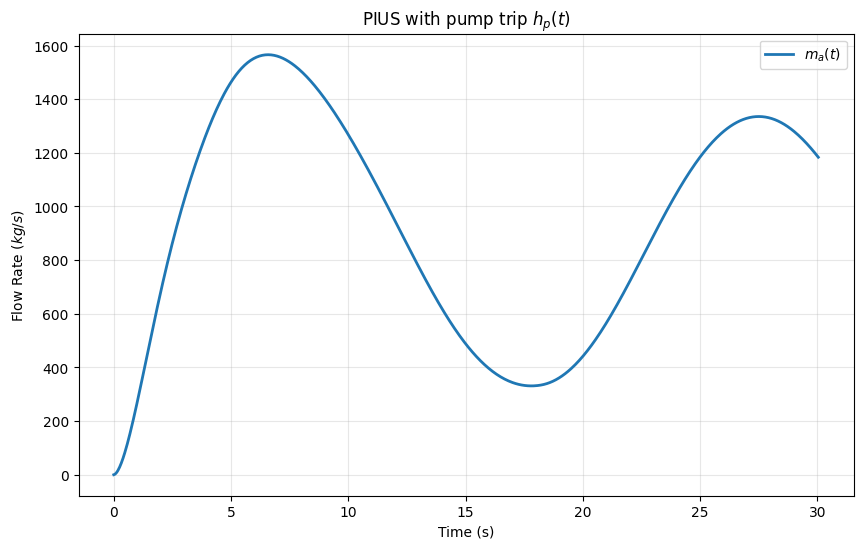

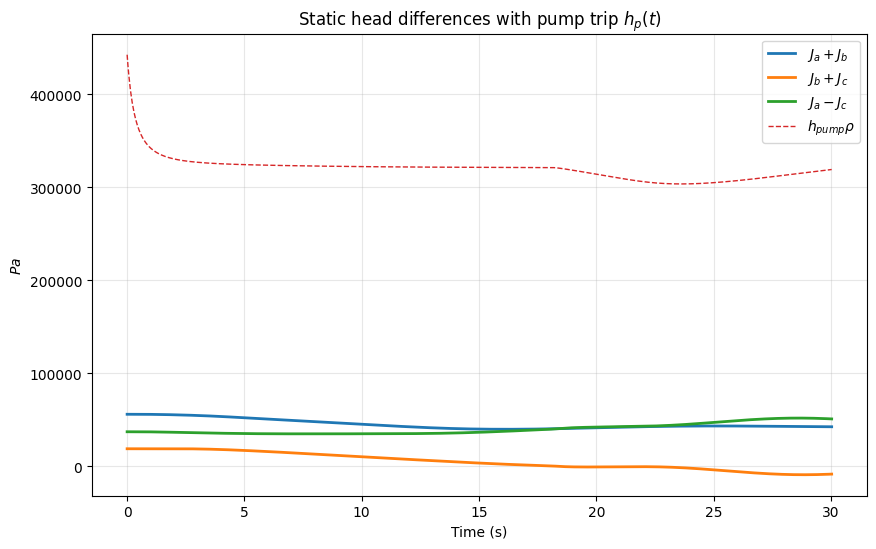

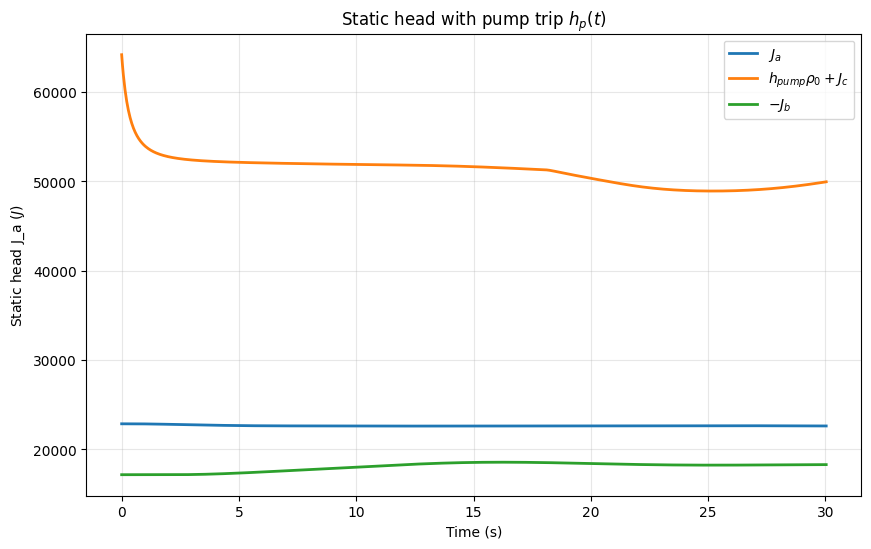

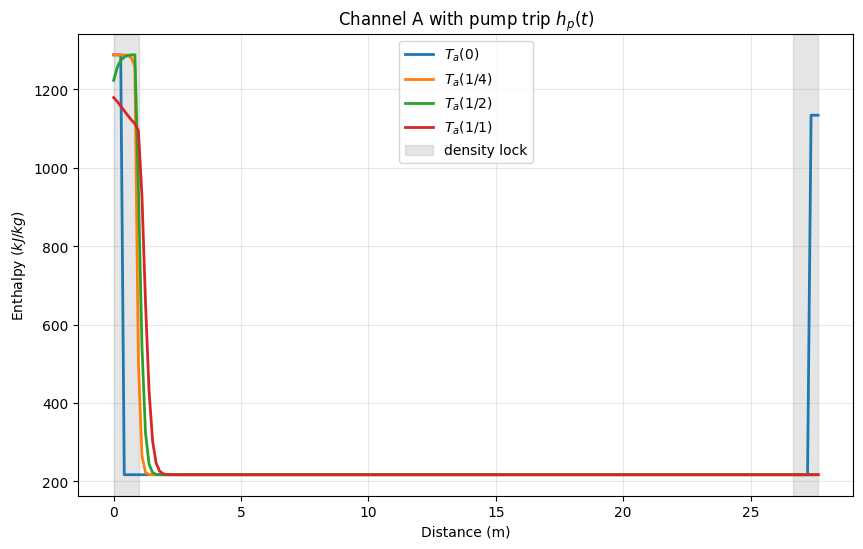

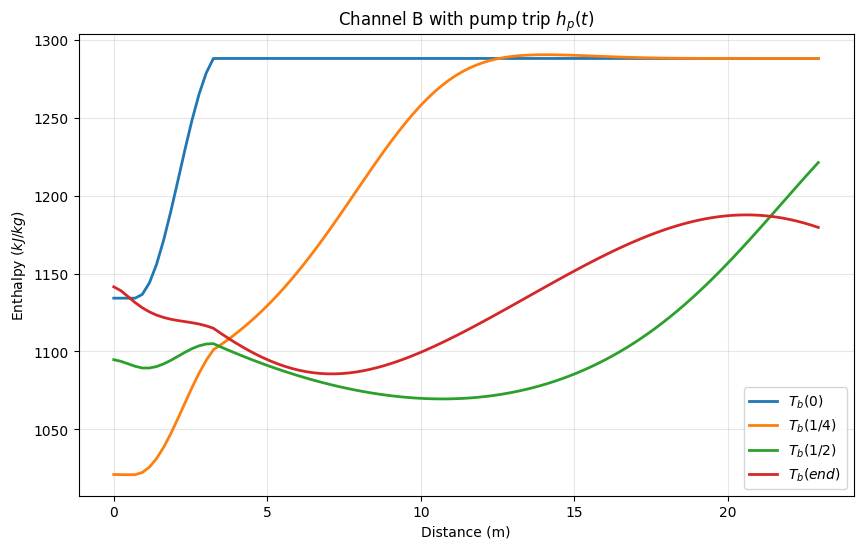

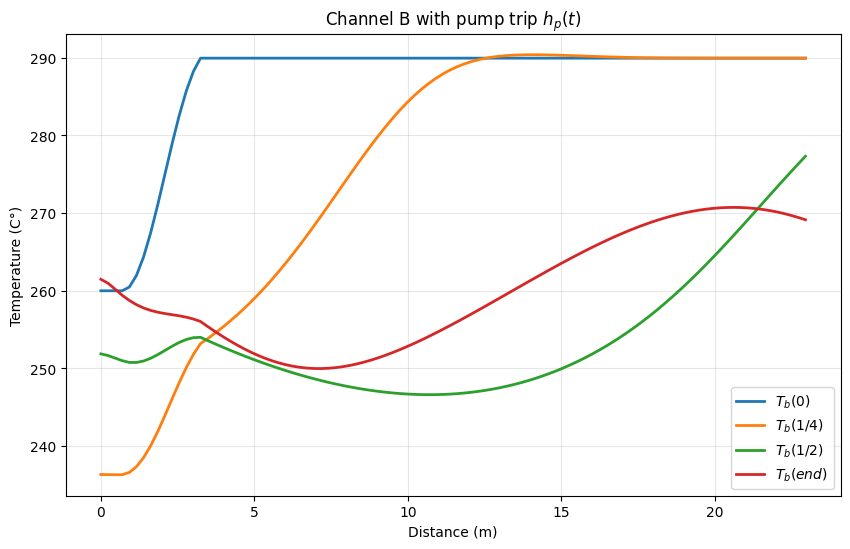

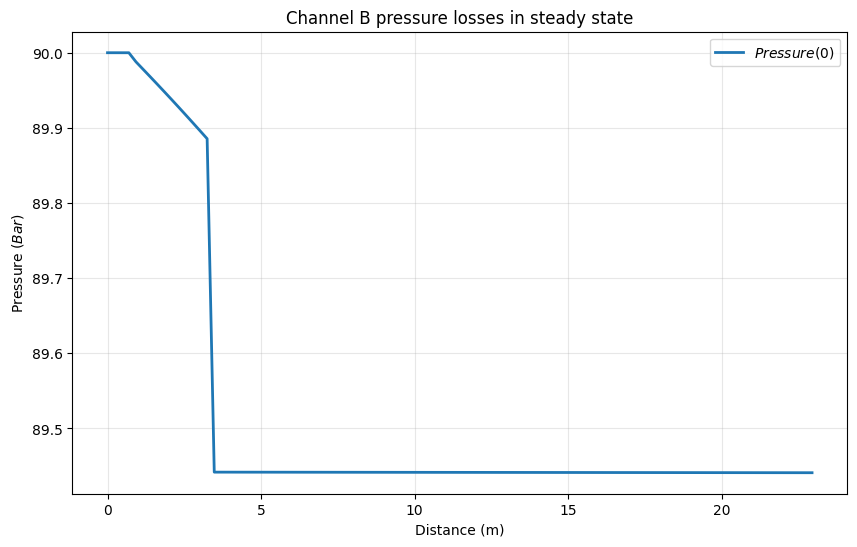

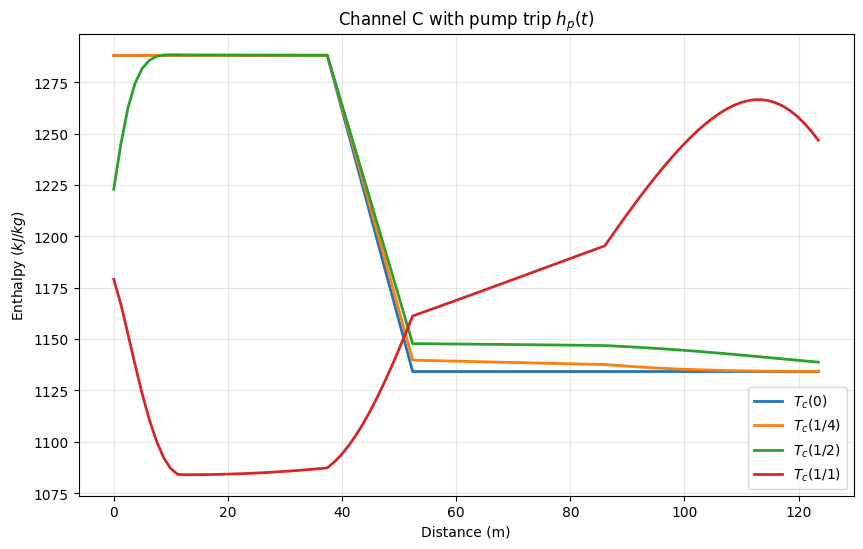

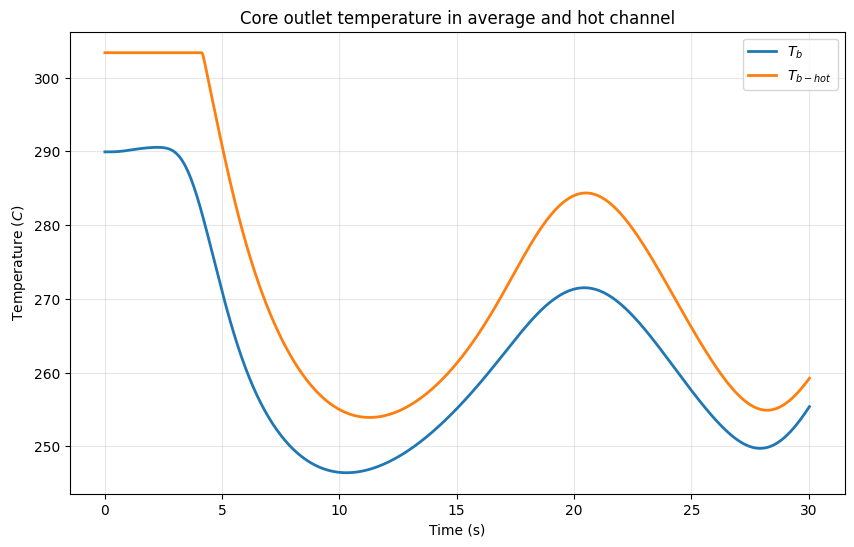

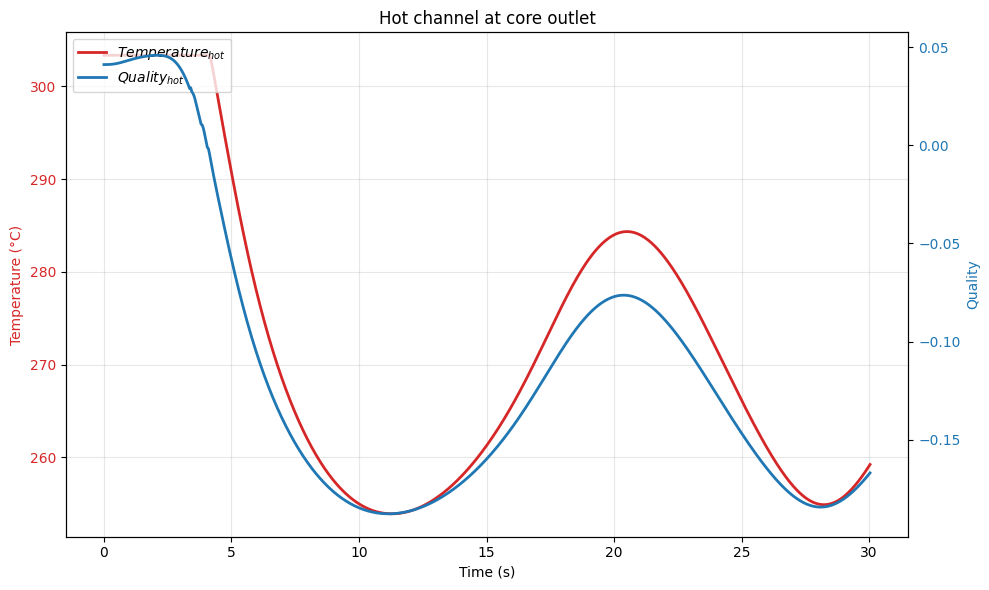

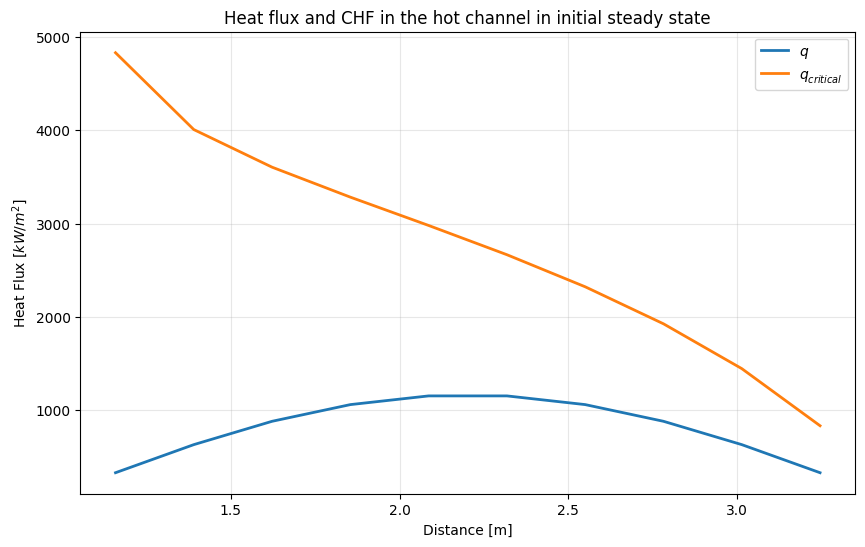

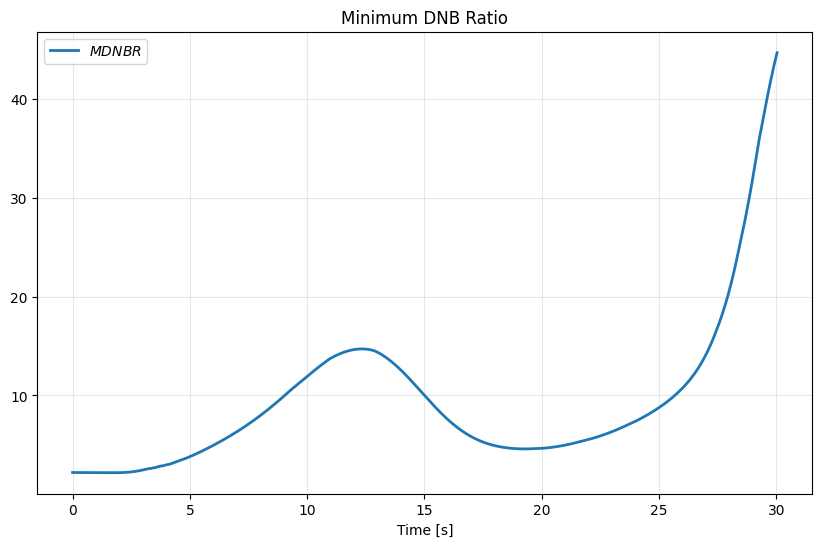

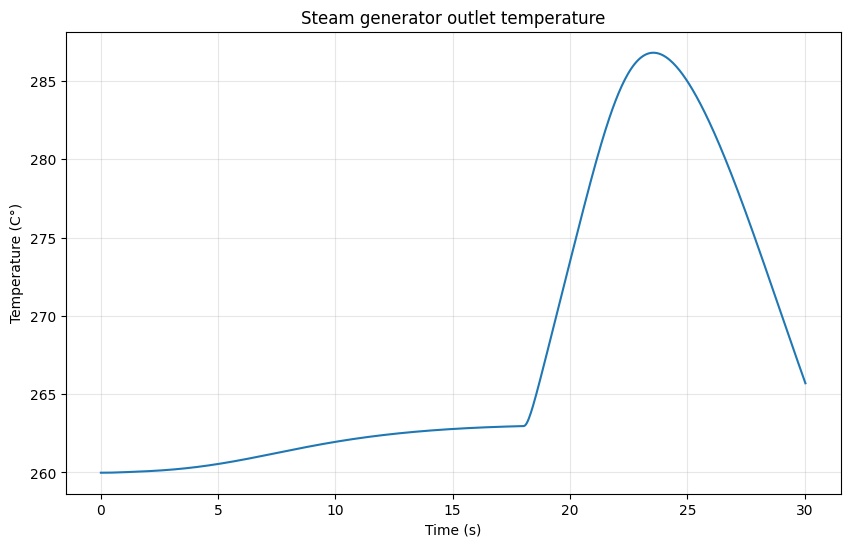

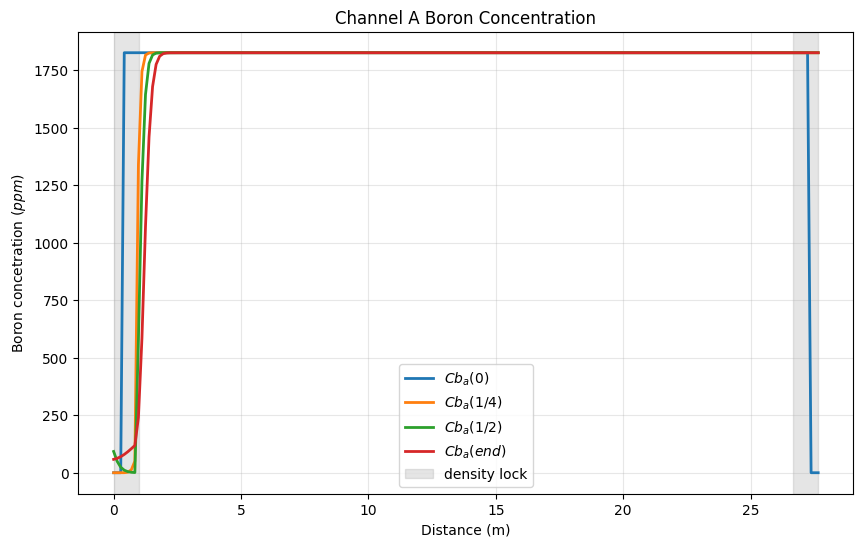

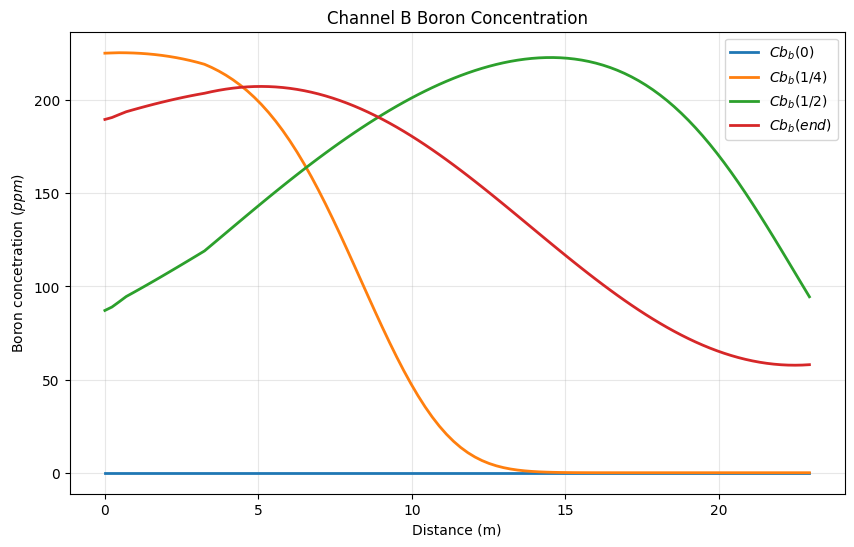

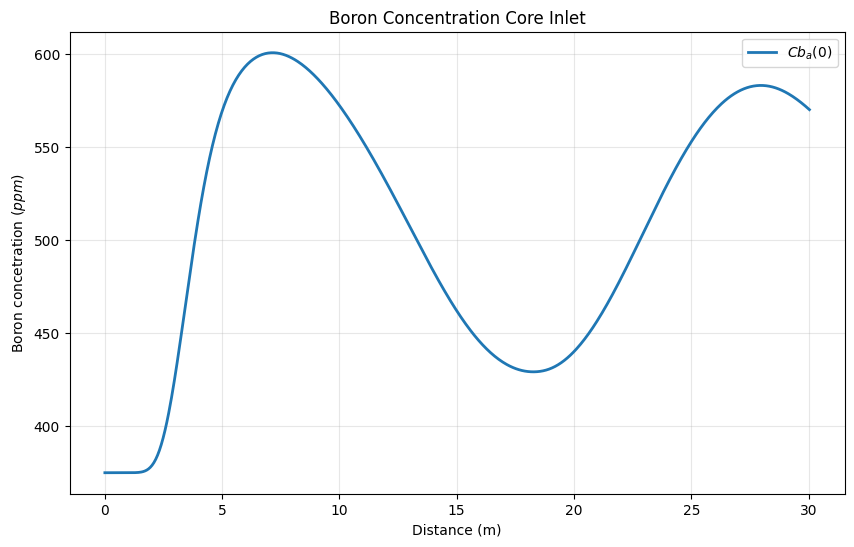

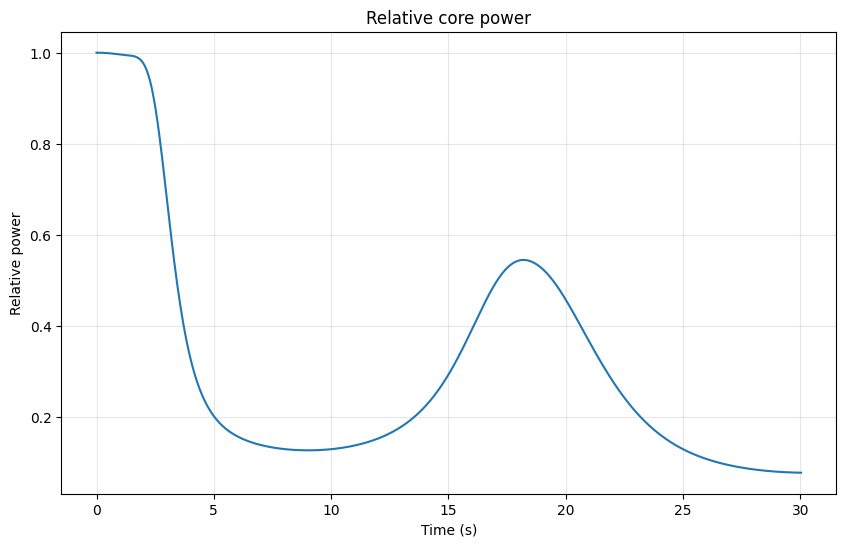

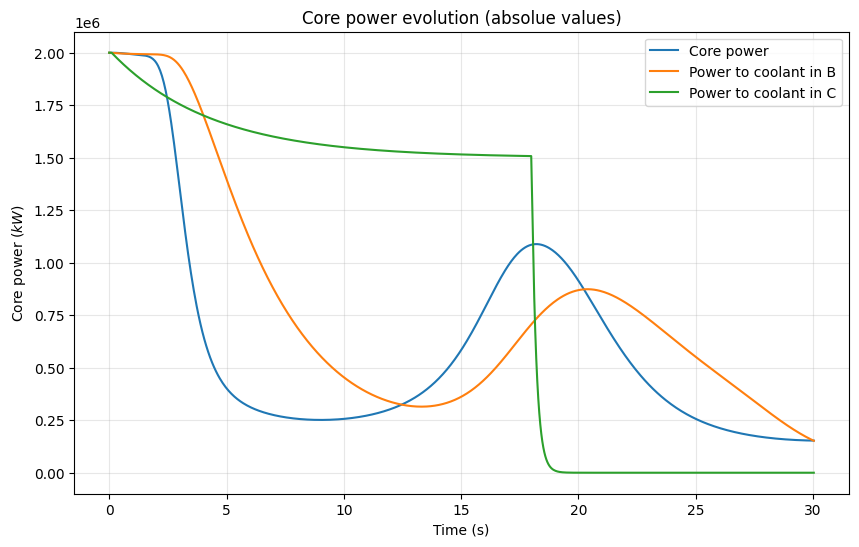

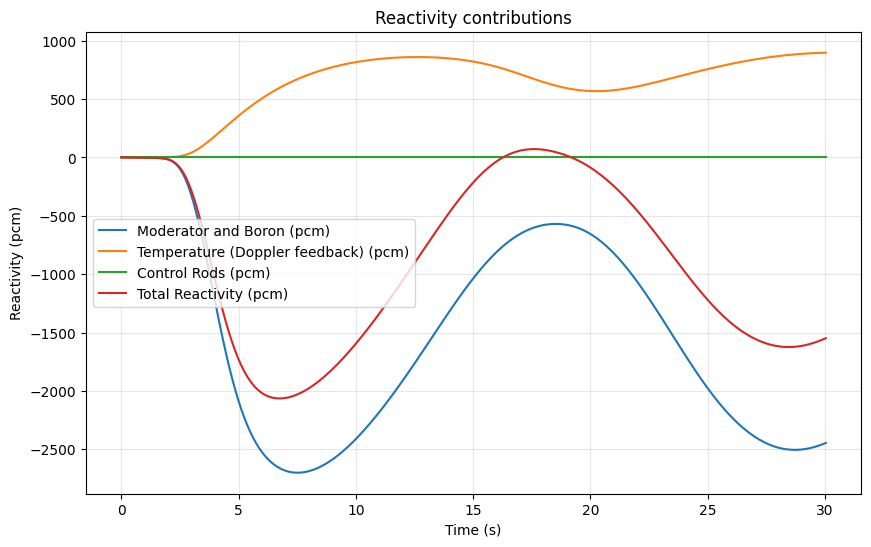

In [33]:
# qa_inf = np.sqrt((J_b + J_a) / (zeta_a + zeta_b) *2 * g / (rho_0)) , only if qc = 0 in steady state
# assuming after a certain time the static heads reach a value that is almost constant. Steady state flows fo rnatural circulation are computed
"""from scipy.optimize import fsolve
c_a = rho_0 * zeta_a / 2
c_b = rho_0 * zeta_b / 2
c_c = rho_0 * zeta_c / 2
def equations(vars):
    qa, qb = vars
    # Equation 1: c_a * qa^2 + c_b * qb^2 - B[0] = 0
    eq1 = c_a * qa**2 + c_b * qb**2 - g * (J_a + J_b)
    # Equation 2: c_c * qa^2 + (c_c + c_b) * qb^2 - 2*c_c * qa * qb - B[1] = 0
    eq2 = c_c * qa**2 + (c_c + c_b) * qb**2 - 2*c_c * (qa * qb) - g * (J_b + J_c)
    return [eq1, eq2]
guess = [5.0, 5.0]
qa_inf, qb_inf = fsolve(equations, guess)
qc_inf = qb_inf - qa_inf"""

plt.figure(figsize=(10, 6))
plt.plot(t, m_j_t[:, 0], label='$m_a(t)$', linewidth=2)
#plt.plot(t, m_j_t[:, 1], label='$m_b(t)$', linewidth=2)
#plt.plot(t, m_j_t[:, 2], label='$m_c(t)$', linewidth=2)
#plt.plot(t, np.full(len(t), qa_inf), label='$q_a(\inf)$', linewidth=1, linestyle = '--')
#plt.plot(t, np.full(len(t), qb_inf), label='$q_b(\inf)$', linewidth=1, linestyle = '--')
#plt.plot(t, np.full(len(t), qc_inf), label='$q_c(\inf)$', linewidth=1, linestyle = '--')
plt.xlabel('Time (s)')
plt.ylabel('Flow Rate ($ kg/s$)')
plt.title('PIUS with pump trip $h_p(t)$')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


plt.figure(figsize=(10, 6))
plt.plot(t, (J_j_t[:, 0] + J_j_t[:, 1]) *g, label='$J_a + J_b $', linewidth=2)
plt.plot(t, (J_j_t[:, 1] + J_j_t[:, 2])* g, label='$J_b + J_c $', linewidth=2)
plt.plot(t, (J_j_t[:, 0] - J_j_t[:, 2])* g, label='$J_a - J_c $', linewidth=2)
plt.plot(t, np.full(len(t), g* h_pump(t) * get_rho(i_c_t[:, n_pump], P_initial)), label=r'$h_{pump} \rho $', linewidth=1, linestyle = '--')
plt.xlabel('Time (s)')
plt.ylabel('$Pa$')
plt.title('Static head differences with pump trip $h_p(t)$')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(t, J_j_t[:, 0], label='$J_a$', linewidth=2)
plt.plot(t, h_pump(t) * get_rho(i_c_t[:, n_pump], P_initial)+ J_j_t[:, 2], label=r'$h_{pump} \rho _0 + J_c$', linewidth=2)
plt.plot(t, -J_j_t[:, 1], label='$-J_b$', linewidth=2)
plt.xlabel('Time (s)')
plt.ylabel('Static head J_a ($J$)')
plt.title('Static head with pump trip $h_p(t)$')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


plt.figure(figsize=(10, 6))
plt.plot(x_a, i_a_t[0, :] , label='$T_a(0)$', linewidth=2)
plt.plot(x_a, i_a_t[int(len(t)/4), :] , label='$T_a(1/4)$', linewidth=2)
plt.plot(x_a, i_a_t[int(len(t)/2), :] , label='$T_a(1/2)$', linewidth=2)
plt.plot(x_a, i_a_t[-1, :] , label='$T_a(1/1)$', linewidth=2)
plt.axvspan(0, L_Udl, color='gray', alpha=0.2, label='density lock')
plt.axvspan(L_a - L_Ldl, L_a, color='gray', alpha=0.2)
plt.xlabel('Distance (m)')
plt.ylabel('Enthalpy ($kJ/kg$)')
plt.title('Channel A with pump trip $h_p(t)$')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(x_b, i_b_t[0, :] , label='$T_b(0)$', linewidth=2)
plt.plot(x_b, i_b_t[int(len(t)/4), :] , label='$T_b(1/4)$', linewidth=2)
plt.plot(x_b, i_b_t[int(len(t)/2), :] , label='$T_b(1/2)$', linewidth=2)
plt.plot(x_b, i_b_t[-1, :] , label='$T_b(end)$', linewidth=2)
plt.xlabel('Distance (m)')
plt.ylabel('Enthalpy ($kJ/kg$)')
plt.title('Channel B with pump trip $h_p(t)$')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(x_b, T_b_t[0, :] , label='$T_b(0)$', linewidth=2)
plt.plot(x_b, T_b_t[int(len(t)/4), :] , label='$T_b(1/4)$', linewidth=2)
plt.plot(x_b, T_b_t[int(len(t)/2), :] , label='$T_b(1/2)$', linewidth=2)
plt.plot(x_b, T_b_t[-1, :] , label='$T_b(end)$', linewidth=2)
plt.xlabel('Distance (m)')
plt.ylabel('Temperature (C°)')
plt.title('Channel B with pump trip $h_p(t)$')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(x_b, P_drop_b , label='$Pressure(0)$', linewidth=2)
plt.xlabel('Distance (m)')
plt.ylabel('Pressure ($Bar$)')
plt.title('Channel B pressure losses in steady state')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(x_c, i_c_t[0, :] , label='$T_c(0)$', linewidth=2)
plt.plot(x_c, i_c_t[int(len(t)/4), :] , label='$T_c(1/4)$', linewidth=2)
plt.plot(x_c, i_c_t[int(len(t)/2), :] , label='$T_c(1/2)$', linewidth=2)
plt.plot(x_c, i_c_t[-1, :] , label='$T_c(1/1)$', linewidth=2)
plt.xlabel('Distance (m)')
plt.ylabel('Enthalpy ($kJ/kg$)')
plt.title('Channel C with pump trip $h_p(t)$')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

'''
plt.figure(figsize=(10, 6))
plt.plot(t, i_a_t[:, 0])
plt.xlabel('Time (s)')
plt.ylabel('Temperature ($C$)')
plt.title('Channel A bottom temperature')
plt.grid(True, alpha=0.3)
plt.show()
'''
plt.figure(figsize=(10, 6))
plt.plot(t, T_b_t[:, idx_exit_core] , label='$T_b$', linewidth=2)
if evaluate_hot: plt.plot(t, T_b_t_hot[:, idx_exit_core] , label='$T_{b-hot}$', linewidth=2)
plt.xlabel('Time (s)')
plt.ylabel('Temperature ($C$)')
plt.title('Core outlet temperature in average and hot channel')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

if evaluate_hot:
    fig, ax1 = plt.subplots(figsize=(10, 6))
    # --- Primary Y-Axis (Temperature) ---
    color1 = 'tab:red'
    ax1.set_xlabel('Time (s)')
    ax1.set_ylabel('Temperature (°C)', color=color1)
    line1 = ax1.plot(t, T_b_t_hot[:, idx_exit_core], label='$Temperature_{hot}$', color=color1, linewidth=2)
    ax1.tick_params(axis='y', labelcolor=color1)
    ax1.grid(True, alpha=0.3)
    # --- Secondary Y-Axis (Quality) ---
    ax2 = ax1.twinx()  # Create a second y-axis sharing the same x-axis
    color2 = 'tab:blue'
    ax2.set_ylabel('Quality', color=color2) 
    line2 = ax2.plot(t, quality_b_t_hot[:, -1], label='$Quality_{hot}$', color=color2, linewidth=2)
    ax2.tick_params(axis='y', labelcolor=color2)
    # Combine the lines and labels from both axes into a single legend
    lines = line1 + line2
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='upper left')
    # (Note: I removed the stray '$' at the end of your original title)
    plt.title('Hot channel at core outlet') 
    fig.tight_layout() # Ensures labels don't get cut off
    plt.show()

if evaluate_CHF:
    plt.figure(figsize=(10, 6))
    plt.plot(x_core[1:], heat_flux_hot_channel_kWm2 , label='$q^{''}$', linewidth=2)
    plt.plot(x_core[1:], CHF_initial * 1e-3 , label='$q^{''}_{critical}$', linewidth=2)
    plt.xlabel('Distance [m]')
    plt.ylabel('Heat Flux [$kW / m^2$]')
    plt.title('Heat flux and CHF in the hot channel in initial steady state')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    plt.figure(figsize=(10, 6))
    plt.plot(t, MDNBR_t , label='$MDNBR$', linewidth=2)
    plt.xlabel('Time [s]')
    plt.title('Minimum DNB Ratio')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

plt.figure(figsize=(10, 6))
plt.plot(t, get_T_from_i(i_c_t[:, idx_exit_SG], P_initial))
plt.xlabel('Time (s)')
plt.ylabel('Temperature (C°)')
plt.title('Steam generator outlet temperature')
plt.grid(True, alpha=0.3)
plt.show()
    
'''
plt.figure(figsize=(10, 6))
plt.plot(t, i_c_t[:, 0])
plt.xlabel('Time (s)')
plt.ylabel('Temperature ($C$)')
plt.title('Channel C bottom temperature')
plt.grid(True, alpha=0.3)
plt.show()
'''
plt.figure(figsize=(10, 6))
plt.plot(x_a, Cb_a_t[0, :] , label='$Cb_a(0)$', linewidth=2)
plt.plot(x_a, Cb_a_t[int(len(t)/4), :] , label='$Cb_a(1/4)$', linewidth=2)
plt.plot(x_a, Cb_a_t[int(len(t)/2), :] , label='$Cb_a(1/2)$', linewidth=2)
plt.plot(x_a, Cb_a_t[-1, :] , label='$Cb_a(end)$', linewidth=2)
plt.axvspan(0, L_Udl, color='gray', alpha=0.2, label='density lock')
plt.axvspan(L_a - L_Ldl, L_a, color='gray', alpha=0.2)
plt.xlabel('Distance (m)')
plt.ylabel('Boron concetration ($ppm$)')
plt.title('Channel A Boron Concentration')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(x_b, Cb_b_t[0, :] , label='$Cb_b(0)$', linewidth=2)
plt.plot(x_b, Cb_b_t[int(len(t)/4), :] , label='$Cb_b(1/4)$', linewidth=2)
plt.plot(x_b, Cb_b_t[int(len(t)/2), :] , label='$Cb_b(1/2)$', linewidth=2)
plt.plot(x_b, Cb_b_t[-1, :] , label='$Cb_b(end)$', linewidth=2)
plt.xlabel('Distance (m)')
plt.ylabel('Boron concetration ($ppm$)')
plt.title('Channel B Boron Concentration')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(t, Cb_b_t[: , idx_start_core] + SS_boron_concentration, label='$Cb_a(0)$', linewidth=2)
plt.xlabel('Distance (m)')
plt.ylabel('Boron concetration ($ppm$)')
plt.title('Boron Concentration Core Inlet')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(t, average_fuel_volumetric_heating_kW_t / average_fuel_volumetric_heating_kW_t[0])
plt.xlabel('Time (s)')
plt.ylabel('Relative power')
plt.title('Relative core power')
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(t, np.abs(Q_core), label='Core power')
plt.plot(t, np.abs(Total_P_b), label='Power to coolant in B')
plt.plot(t, np.abs(Total_P_c), label='Power to coolant in C')
plt.xlabel('Time (s)')
plt.ylabel('Core power ($kW$)')
plt.title('Core power evolution (absolue values)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# reactivity evolution
if nonlinear_PK:
    total_moderator_boron_reactivity = p(T_avg_core_t, Cb_avg_t+SS_boron_concentration, MB_3rd_degree_polynomial_interpolation_coeffs) + MB_normalization_constant
    total_doppler_reactivity = (T_avg_fuel_t - T_avg_fuel_t[0]) * alpha_doppler
    total_CR_reactivity = rho_CR_func(t)
    total_reactivity = total_moderator_boron_reactivity + total_doppler_reactivity + total_CR_reactivity
    plt.figure(figsize=(10, 6))
    plt.plot(t, total_moderator_boron_reactivity, label=f'Moderator and Boron (pcm)')
    plt.plot(t, total_doppler_reactivity, label=f'Temperature (Doppler feedback) (pcm)')
    plt.plot(t, total_CR_reactivity, label=f'Control Rods (pcm)')
    plt.plot(t, total_reactivity, label=f'Total Reactivity (pcm)')
    plt.xlabel('Time (s)')
    plt.ylabel('Reactivity (pcm)')
    plt.title('Reactivity contributions')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
else:
    total_boron_reactivity = (Cb_avg_t - Cb_avg_t[0]) * alpha_B  # in pcm, in the point kinetics function it's not in pcm
    total_moderator_reactivity = (T_avg_core_t - T_avg_core_t[0]) * alpha_M
    total_doppler_reactivity = (T_avg_fuel_t - T_avg_fuel_t[0]) * alpha_doppler
    total_CR_reactivity = rho_CR_func(t)
    total_reactivity = total_boron_reactivity + total_moderator_reactivity + total_doppler_reactivity + total_CR_reactivity
    plt.figure(figsize=(10, 6))
    plt.plot(t, total_boron_reactivity, label=f'Boron (pcm)')
    plt.plot(t, total_moderator_reactivity, label=f'Temperature (Moderator) (pcm)')
    plt.plot(t, total_doppler_reactivity, label=f'Temperature (Doppler feedback) (pcm)')
    plt.plot(t, total_CR_reactivity, label=f'Control Rods (pcm)')
    plt.plot(t, total_reactivity, label=f'Total Reactivity (pcm)')
    plt.xlabel('Time (s)')
    plt.ylabel('Reactivity (pcm)')
    plt.title('Reactivity contributions')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()



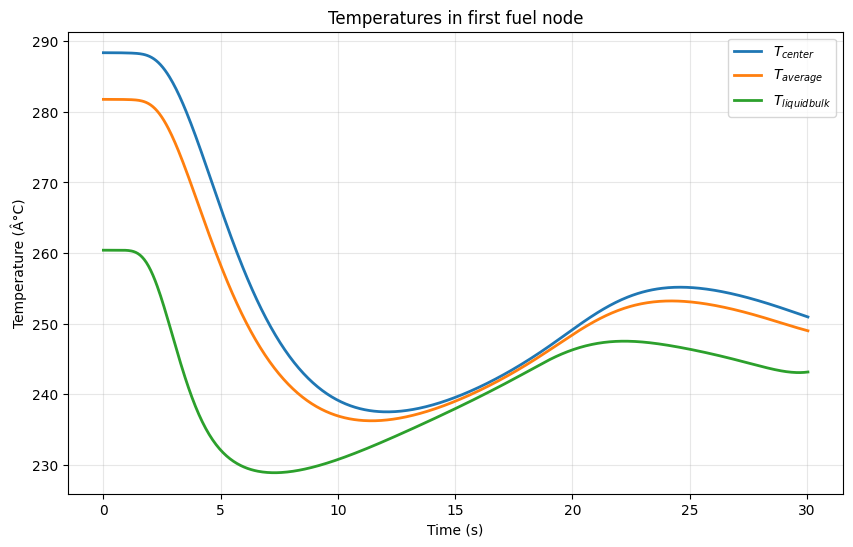

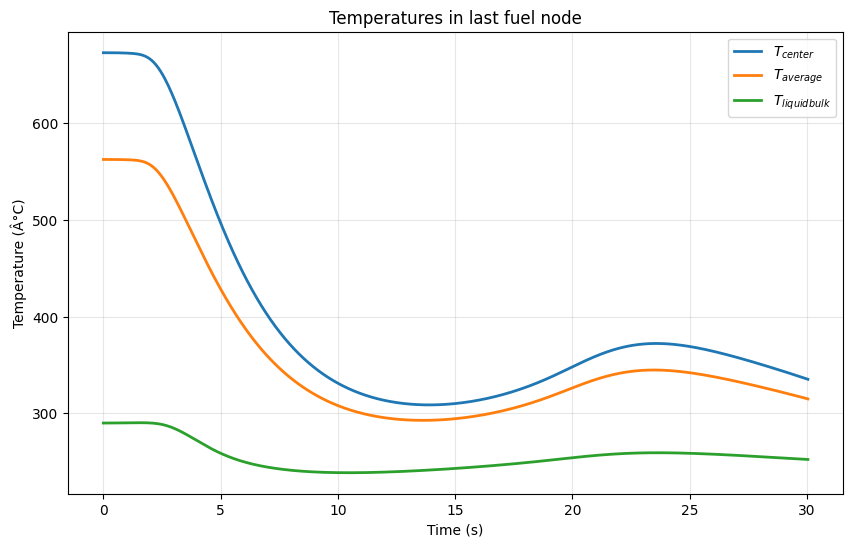

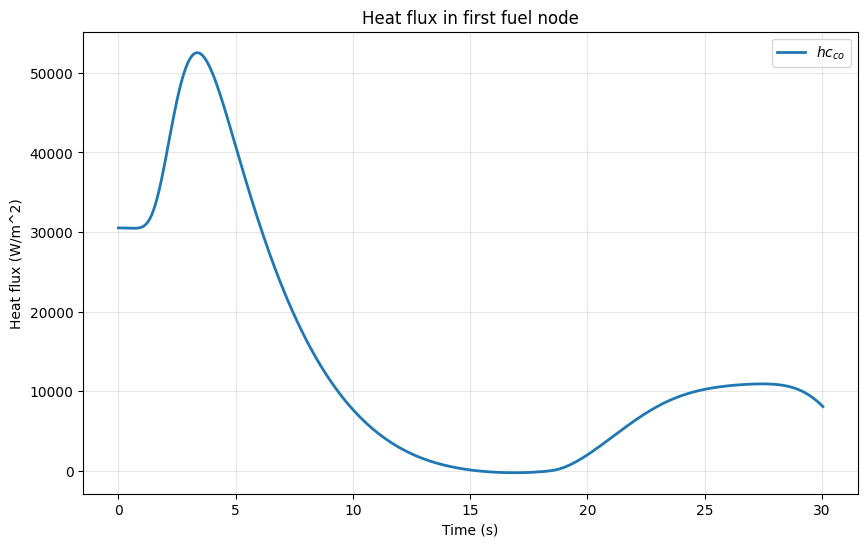

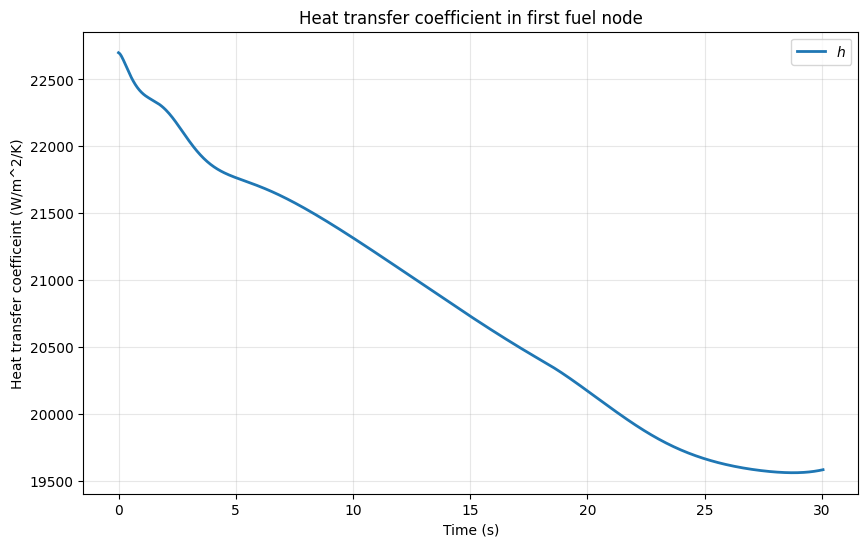

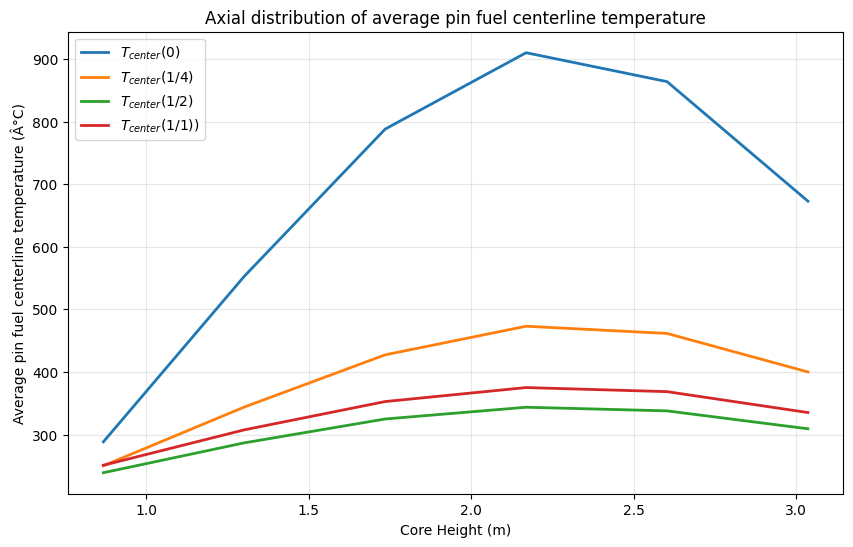

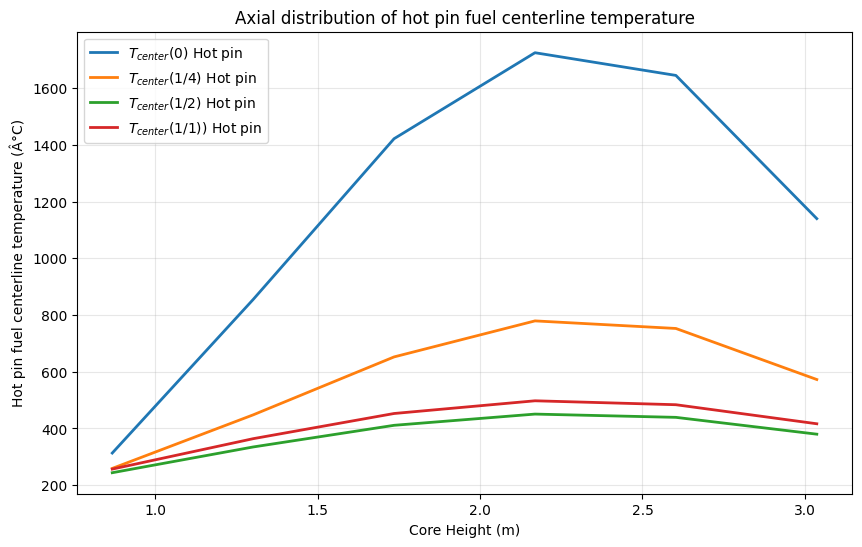

In [28]:
fuel_nodes = []
hot_fuel_nodes = []
first_fuel_node = None
last_fuel_node = None
for i in range(len(core)):
    if core[i] is not None:
        fuel_nodes.append(core[i])
        if evaluate_hot : hot_fuel_nodes.append(core_hot[i])
        if first_fuel_node is None:
            first_fuel_node = core[i]
        last_fuel_node = core[i]

# Evolution of first node temperatures
plt.figure(figsize=(10, 6))
plt.plot(first_fuel_node.t, first_fuel_node.T_centerline , label=r'$T_{center}$', linewidth=2)
plt.plot(first_fuel_node.t, first_fuel_node.average_fuel_T , label=r'$T_{average}$', linewidth=2)
plt.plot(first_fuel_node.t, first_fuel_node.T_lb, label=r'$T_{liquid bulk}$', linewidth=2)
plt.xlabel('Time (s)')
plt.ylabel('Temperature (Â°C)')
plt.title('Temperatures in first fuel node')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(last_fuel_node.t, last_fuel_node.T_centerline , label=r'$T_{center}$', linewidth=2)
plt.plot(last_fuel_node.t, last_fuel_node.average_fuel_T , label=r'$T_{average}$', linewidth=2)
plt.plot(last_fuel_node.t, last_fuel_node.T_lb, label=r'$T_{liquid bulk}$', linewidth=2)
plt.xlabel('Time (s)')
plt.ylabel('Temperature (Â°C)')
plt.title('Temperatures in last fuel node')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(first_fuel_node.t, first_fuel_node.hf_co , label=r'$hc_{co}$', linewidth=2)
plt.xlabel('Time (s)')
plt.ylabel('Heat flux (W/m^2)')
plt.title('Heat flux in first fuel node')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(first_fuel_node.t, first_fuel_node.h , label=r'$h$', linewidth=2)
plt.xlabel('Time (s)')
plt.ylabel('Heat transfer coefficeint (W/m^2/K)')
plt.title('Heat transfer coefficient in first fuel node')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()



# Axial distribution of average pin centerline temperature
zs = [node.z for node in fuel_nodes]
center_T_init = [node.T_centerline[0] for node in fuel_nodes]
center_T_quarter = [node.T_centerline[int(len(t)/4)] for node in fuel_nodes]
center_T_middle = [node.T_centerline[int(len(t)/2)] for node in fuel_nodes]
center_T_end = [node.T_centerline[-1] for node in fuel_nodes]
plt.figure(figsize=(10, 6))
plt.plot(zs, center_T_init , label=r'$T_{center}(0)$', linewidth=2)
plt.plot(zs, center_T_quarter, label=r'$T_{center}(1/4)$', linewidth=2)
plt.plot(zs, center_T_middle, label=r'$T_{center}(1/2)$', linewidth=2)
plt.plot(zs, center_T_end, label=r'$T_{center}(1/1))$', linewidth=2)
plt.xlabel('Core Height (m)')
plt.ylabel('Average pin fuel centerline temperature (Â°C)')
plt.title('Axial distribution of average pin fuel centerline temperature')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Axial distribution of hot pin centerline temperature
if evaluate_hot :
    zs = [node.z for node in hot_fuel_nodes]
    center_T_init = [node.T_centerline[0] for node in hot_fuel_nodes]
    center_T_quarter = [node.T_centerline[int(len(t)/4)] for node in hot_fuel_nodes]
    center_T_middle = [node.T_centerline[int(len(t)/2)] for node in hot_fuel_nodes]
    center_T_end = [node.T_centerline[-1] for node in hot_fuel_nodes]
    plt.figure(figsize=(10, 6))
    plt.plot(zs, center_T_init , label=r'$T_{center}(0)$ Hot pin', linewidth=2)
    plt.plot(zs, center_T_quarter, label=r'$T_{center}(1/4)$ Hot pin', linewidth=2)
    plt.plot(zs, center_T_middle, label=r'$T_{center}(1/2)$ Hot pin', linewidth=2)
    plt.plot(zs, center_T_end, label=r'$T_{center}(1/1))$ Hot pin', linewidth=2)
    plt.xlabel('Core Height (m)')
    plt.ylabel('Hot pin fuel centerline temperature (Â°C)')
    plt.title('Axial distribution of hot pin fuel centerline temperature')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

